# Which open models obey a five-algorithm ban, and where do the survivors land in activation space?

**Artifact `art_R-HSmXq2t97f`** (iteration 8, experiment 44) of the study *prompt bans substitute, not just subtract*, on the **T1 grid-path task**: *write `solve(grid, start, goal)` that returns a path between two cells of a 4-connected grid.*

Asked plainly, every open model tested writes BFS (or DFS). This experiment bans each model's own five most-used algorithms **by name**. It then asks two questions:

1. **Who obeys?** Which models then write a *correct* program built on a different algorithm (a *correct survivor*)?
2. **Where do the survivors land?** For the model that obeys most, where do those survivors sit on the model's own 10-algorithm activation manifold? At the **EDGE** of the banned five (nearest the banned region), or on the **OPPOSITE** side?

The original `method.py` is an orchestrator with one sub-command per stage:
`stage0 | smoke | commit1 | screen_base | commit2 | screen_ban | adjudicate | select | states | geometry | m2 | quantcheck | confirm | novelty | positioning | figures | rederive | outputs`

| Stage(s) | What the full run did | In this notebook |
|---|---|---|
| `screen_base`, `screen_ban`, `adjudicate` | 8 new open-model configurations (+2 carried) sampled via OpenRouter / local vLLM; the ban prompt names B_c = {BFS, DFS, IDDFS, A*, greedy best-first}; every program run on a 48-case hidden test suite, labelled by a 10-class runtime/AST labeller and adjudicated by gated LLM judges | not re-run (API keys, GPU, sandbox); the labelled outcomes are loaded |
| `select` | committed rule: Q = {c : share of correct survivors ≥ 0.20}, m\* = best share | **run** (§2) |
| `states` | S-mean residual-stream states of Qwen3-32B (nf4, truncated decoder, 16 GB GPU) for 300 forced prompts ("Implement X for this task") + 17 baseline / ban prompts | not re-run; 100 of the 300 forced states (10 per algorithm) and the 17 others are loaded, blocks 29–33 |
| `geometry` | layer choice L\*, PCA / classical MDS / Isomap geodesics, EDGE / MIDDLE / OPPOSITE classes, reliability, landing nulls, robustness grid, overlays, figures F2–F4 and F6 | **run** (§3–§6) |
| `confirm`, `figures` | frozen geometry, then 50 held-out ban prompts; figures F1 and F7 | landing on the frozen geometry and the figures **run** (§7, §10) |
| `circle`, `t8` | persistent homology ("is it a circle?"); synthetic-ring test of the whole pipeline | **run** (§8, §9) |

All functions are copied from `src/common.py`, `src/screen.py`, `src/geometry.py`, `src/landing.py`, `src/figures.py` and `src/stages.py` with no changes to their logic. Only file reads and writes are replaced by the loaded `data`. Because the demo has 100 of the 300 forced points, its numbers differ somewhat from the full run; the last cell lists both side by side.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# numpy, scipy, scikit-learn, matplotlib, Cython — pre-installed on Colab, install locally only (Colab's exact versions).
# Installed first so that ripser / persim below resolve against these versions instead of pulling newer ones.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'Cython==3.0.12')

# loguru (logging in the original code), ripser (persistent homology, stages `circle` and `t8`) — NOT on Colab, always install
_pip('loguru==0.7.3', 'ripser==0.6.15')

In [2]:
from __future__ import annotations

# --- method.py
import sys
from pathlib import Path

from loguru import logger

# --- src/common.py, src/screen.py, src/landing.py, src/stages.py
import collections
import itertools
import math
import time
from typing import Any

# --- src/geometry.py
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import spearmanr

# --- src/figures.py (without matplotlib.use("Agg"), so that the figures render inline)
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# --- notebook only: decode the base64 float16 states; silence scipy's sparse-efficiency notices and print
#     warnings without the local file path of the library that raised them
import base64
import warnings
from scipy.sparse import SparseEfficiencyWarning

warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-8/experiment-44/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["title"])
print(f"{len(data['examples'])} forced-prompt states + {len(data['overlay_prompts'])} overlay prompt states | "
      f"{meta['states']['repo']} [{meta['states']['precision']}] | blocks {meta['states']['blocks']} | "
      f"hidden size {meta['states']['hidden_size']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Top-five ban: which open models obey, and where the survivors land on the activation manifold
100 forced-prompt states + 17 overlay prompt states | unsloth/Qwen3-32B-bnb-4bit [nf4] | blocks [29, 30, 31, 32, 33] | hidden size 5120


## Configuration

The tunable parameters below only set how many random draws the statistical tests use; they do not change which data are analysed. The comments give the full-run values, which also fit in this notebook's time budget.

Fixed by the data, so not tunable here:
- 10 forced prompts per algorithm (the full run used 30, i.e. 300 points);
- blocks 29–33, i.e. L\* = 31 ± 2;
- the committed Isomap neighbourhood sizes k ∈ {5, 10, 15}.

In [5]:
# ---------------------------------------------------------------- tunable parameters
# Set to the original full-run values: they fit the 10-minute budget (about 1 min of compute on 2 CPUs).
# Smallest values that still produce every output (first test run): 10 / 1000 / 500 / 5 / 10 / 2.
N_BOOT = 1000            # bootstrap resamples of the paraphrase groups (bootstrap)          original: 1000
NULL_DRAWS = 10000       # iid draws of the landing nulls U, F and C (landing)               original: 10000
ROBUSTNESS_DRAWS = 4000  # null draws per cell of the block x k robustness grid              original: 4000
CIRCLE_NULLS = 100       # covariance-matched Gaussian clouds per H1 test (stage `circle`)   original: 100
T8_RANDOM = 200          # random-survivor placebo runs on the synthetic ring (stage `t8`)   original: 200
T8_NULLS = 20            # Gaussian null clouds for the ring's H1 test (stage `t8`)          original: 20

## 1. Frozen protocol (`src/common.py`)

One shared definition of the protocol, used by every stage:
- the 10-algorithm **catalogue**, whose canonical order fixes the order of every table and plot;
- the screen **configurations** C1–C8 (C9 and C10 are carried from earlier iterations);
- the checkpoints used for activation states;
- the committed **selection rule**;
- the Wilson score interval used for every share.

Only the pieces used below are copied, verbatim. The original `setup_logging` also writes a rotating log file; here it logs to the notebook only.

In [6]:
CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
DISPLAY = {
    "bfs": "breadth-first search (BFS)", "dfs": "depth-first search (DFS)", "bibfs": "bidirectional BFS",
    "iddfs": "iterative deepening DFS (IDDFS)", "astar": "A* search", "gbfs": "greedy best-first search",
    "dijkstra_unit": "unit-weight Dijkstra", "idastar": "IDA* search", "jps": "jump point search",
    "biastar": "bidirectional A* search",
}
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "BiBFS", "iddfs": "IDDFS", "astar": "A*", "gbfs": "GBFS",
         "dijkstra_unit": "Dijkstra(u)", "idastar": "IDA*", "jps": "JPS", "biastar": "BiA*", "other": "other",
         "no_code": "no code", "invalid": "invalid"}
FILL_ORDER = ["bfs", "dfs", "gbfs", "iddfs", "astar"]

# ---------------------------------------------------------------------------------------------- configurations
CONFIGS: dict[str, dict[str, Any]] = {
    "C1": {"name": "qwen3-8b-think", "family": "Qwen3", "params_b": 8.2, "engine": "local-vllm",
           "model": "Qwen/Qwen3-8B-FP8", "hf_repo": "Qwen/Qwen3-8B", "thinking": True, "n_base": 30, "n_ban": 50,
           "provider": "local vLLM 0.11.0 (eager)", "quantization": "fp8 (official FP8 checkpoint, W8A16 Marlin)",
           "local": True},
    "C2": {"name": "llama-3.1-8b", "family": "Llama-3.1", "params_b": 8.0, "engine": "openrouter",
           "model": "meta-llama/llama-3.1-8b-instruct", "hf_repo": "meta-llama/Llama-3.1-8B-Instruct",
           "thinking": False, "n_base": 100, "n_ban": 50, "provider": None, "quantization": "bf16", "local": False},
    "C3": {"name": "qwen3-14b-off", "family": "Qwen3", "params_b": 14.8, "engine": "openrouter",
           "model": "qwen/qwen3-14b", "hf_repo": "Qwen/Qwen3-14B", "thinking": False, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C4": {"name": "qwen3-14b-on", "family": "Qwen3", "params_b": 14.8, "engine": "openrouter",
           "model": "qwen/qwen3-14b", "hf_repo": "Qwen/Qwen3-14B", "thinking": True, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C5": {"name": "qwen3-32b-off", "family": "Qwen3", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen3-32b", "hf_repo": "Qwen/Qwen3-32B", "thinking": False, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C6": {"name": "qwen3-32b-on", "family": "Qwen3", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen3-32b", "hf_repo": "Qwen/Qwen3-32B", "thinking": True, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    # C7 planned as google/gemma-3-12b-it (DeepInfra bf16); its endpoints timed out (504 after 300 s) in the smoke
    # test and no other bf16/fp8 provider exists -> same-family substitute (deviation D11, decided before commit #1).
    "C7": {"name": "gemma-3-27b-it", "family": "Gemma-3", "params_b": 27.4, "engine": "openrouter",
           "model": "google/gemma-3-27b-it", "hf_repo": "google/gemma-3-27b-it", "thinking": False, "n_base": 100,
           "n_ban": 50, "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C8": {"name": "qwen2.5-coder-32b", "family": "Qwen2.5-Coder", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen-2.5-coder-32b-instruct", "hf_repo": "Qwen/Qwen2.5-Coder-32B-Instruct",
           "thinking": False, "n_base": 100, "n_ban": 50, "provider": "Cloudflare", "quantization": "unknown",
           "local": False},
}
# Precision ladder for states of a selected model (Stage 6 commit #3).
STATE_CHECKPOINTS = {
    "C1": {"repo": "Qwen/Qwen3-8B", "precision": "bf16"},
    "C2": {"repo": "meta-llama/Llama-3.1-8B-Instruct", "precision": "bf16"},
    "C3": {"repo": "Qwen/Qwen3-14B", "precision": "int8"},
    "C4": {"repo": "Qwen/Qwen3-14B", "precision": "int8"},
    "C5": {"repo": "unsloth/Qwen3-32B-bnb-4bit", "precision": "nf4"},
    "C6": {"repo": "unsloth/Qwen3-32B-bnb-4bit", "precision": "nf4"},
    "C7": {"repo": "unsloth/gemma-3-27b-it-bnb-4bit", "precision": "nf4"},
    "C8": {"repo": "unsloth/Qwen2.5-Coder-32B-Instruct-bnb-4bit", "precision": "nf4"},
}
DEPTH_RANGE = (0.30, 0.70)
SELECTION = {"threshold_share_cs": 0.20, "tie_window": 0.02,
             "tie_breaks": ["higher Wilson lower bound", "fewer parameters", "local engine"]}


# ---------------------------------------------------------------------------------------------- logging + io
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # notebook: the original also adds logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


# ---------------------------------------------------------------------------------------------- statistics
Z95 = 1.959963984540054


def wilson_ci(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def wilson_upper_one_sided(k: int, n: int) -> float:
    """One-sided 95% upper bound (Wilson with z = 1.645)."""
    return wilson_ci(k, n, z=1.6448536269514722)[1]


setup_logging("method_notebook")      # method.py: setup_logging(f"method_{stage}")

## 2. Stage `select`: who obeys the ban? (`src/screen.py`)

**Banned set B_c** (commit #2). Each configuration's baseline (no ban) defines its own banned set: the five catalogue algorithms it implemented most. If fewer than five appear, the set is filled from `FILL_ORDER`. Every baseline is BFS/DFS only, so the fill rule gives the *same* five for every configuration: BFS, DFS, IDDFS, A* and greedy best-first.

**Correct survivor.** A ban-arm program that meets both conditions:
- it passes the hidden test suite;
- its adjudicated mechanism is outside B_c: either a non-banned catalogue algorithm, or a *named* known algorithm outside the catalogue (`other` with a name, e.g. Bellman-Ford).

**Selection rule** (commit #3):
- Q = the configurations whose correct-survivor share is ≥ 0.20;
- m\* = the configuration in Q with the highest share;
- ties within 0.02 go to the higher Wilson lower bound, then fewer parameters, then the local engine.

The three functions below are verbatim. In the original, `screen_table()` builds each configuration's metrics from `data/labelled_<cfg>_ban.jsonl` with `config_metrics()`. Here the per-configuration counts come from `mini_demo_data.json`, and the shares and Wilson bounds are recomputed with the same formulas.

In [7]:
CATALOGUE = set(CANON_ORDER)


def banned_set(rows: list[dict[str, Any]]) -> tuple[list[str], dict[str, Any]]:
    """Top five by implemented count (adjudicated label, pass or fail, 'invalid'/'other' excluded); ties -> higher
    correct count, then canonical order; fewer than 5 classes with count >= 1 -> fill from FILL_ORDER."""
    impl = collections.Counter(r["adj_label"] for r in rows if r["adj_label"] in CATALOGUE)
    corr = collections.Counter(r["adj_label"] for r in rows if r["adj_label"] in CATALOGUE and r.get("passed"))
    ranked = sorted([a for a in CANON_ORDER if impl[a] >= 1],
                    key=lambda a: (-impl[a], -corr[a], CANON_ORDER.index(a)))
    b = ranked[:5]
    filled = []
    for a in FILL_ORDER:
        if len(b) >= 5:
            break
        if a not in b:
            b.append(a)
            filled.append(a)
    return sorted(b, key=CANON_ORDER.index), {"implemented": dict(impl), "correct": dict(corr), "filled": filled,
                                             "ranked_with_count": ranked}


def is_correct_survivor(r: dict[str, Any], banned: list[str], include_unresolved: bool = False) -> bool:
    if not r.get("passed"):
        return False
    lab = r.get("adj_label")
    if lab in banned or lab in ("invalid", "no_code", None):
        return False
    if lab in CATALOGUE:
        return True
    if lab == "other":
        return bool(r.get("adj_other_name")) or include_unresolved
    return False


def select(tab: dict[str, Any]) -> dict[str, Any]:
    """Committed rule (new configurations only; carried rows are context)."""
    new = {c: m for c, m in tab.items() if not m.get("carried")}
    q = {c: m for c, m in new.items() if (m["share_cs"] or 0) >= SELECTION["threshold_share_cs"]}
    out: dict[str, Any] = {"Q": sorted(q), "threshold": SELECTION["threshold_share_cs"],
                           "shares": {c: m["share_cs"] for c, m in tab.items()},
                           "upper95_one_sided": {c: m["share_cs_upper95_one_sided"] for c, m in tab.items()}}
    if q:
        best = max(m["share_cs"] for m in q.values())
        tied = [c for c, m in q.items() if best - m["share_cs"] <= SELECTION["tie_window"]]
        tied.sort(key=lambda c: (-q[c]["share_cs_wilson95"][0], q[c]["params_b"], 0 if q[c].get("local") else 1))
        out.update({"m_star": tied[0], "tied": tied, "mode": "SELECTED",
                    "TP_RESULT": f"{tied[0]} ({CONFIGS[tied[0]]['name']}) obeys: share_cs = {q[tied[0]]['share_cs']:.2f}"})
    else:
        most = max(new, key=lambda c: (new[c]["n_correct_survivors"], -new[c]["params_b"]))
        if all(new[c]["n_correct_survivors"] == 0 for c in new):
            most = "C1"
        out.update({"m_star": most, "mode": "DESCRIPTIVE",
                    "TP_RESULT": "no tested open model obeys a five-name ban on this task"})
    return out

**B_c of every configuration (commit #2).** `banned_set()` only counts labels, so each baseline's rows are rebuilt from its composition. The `passed` flag would only break ties, and there are none.

In [8]:
# stage_commit2(): B_c per configuration from its baseline (rows rebuilt from the baseline composition)
summ = meta["screen_summary"]
for cid, mt in summ.items():
    if mt.get("carried"):
        continue
    rows = [{"adj_label": a} for a, c in mt["baseline_composition"].items() for _ in range(c)]
    b, info = banned_set(rows)
    print(f"{cid:3s} baseline {str(mt['baseline_composition']):36s} -> B_c = {b}  filled {info['filled']}  "
          f"(= committed: {b == mt['banned_set']})")

C1  baseline {'bfs': 30}                          -> B_c = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']  filled ['dfs', 'gbfs', 'iddfs', 'astar']  (= committed: True)
C2  baseline {'bfs': 77, 'dfs': 20, 'other': 3}   -> B_c = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']  filled ['gbfs', 'iddfs', 'astar']  (= committed: True)
C3  baseline {'bfs': 94, 'dfs': 6}                -> B_c = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']  filled ['gbfs', 'iddfs', 'astar']  (= committed: True)
C4  baseline {'bfs': 96, 'dfs': 4}                -> B_c = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']  filled ['gbfs', 'iddfs', 'astar']  (= committed: True)
C5  baseline {'bfs': 81, 'dfs': 19}               -> B_c = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']  filled ['gbfs', 'iddfs', 'astar']  (= committed: True)
C6  baseline {'invalid': 9, 'bfs': 91}            -> B_c = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']  filled ['dfs', 'gbfs', 'iddfs', 'astar']  (= committed: True)
C7  baseline {'bfs': 99}                          

**Screen table and the committed selection** (`stage_select`). The screen covers 8 new configurations plus 2 carried rows. Carried rows are context only and are never selected.

In [9]:
# screen_table(): share of correct survivors per configuration with Wilson 95% bounds (counts from the mini data;
# the original derives them from data/labelled_<cfg>_ban.jsonl via config_metrics())
tab = {}
for cid, mt in summ.items():
    n, k = mt["n"], mt["n_correct_survivors"]
    tab[cid] = {**mt, "share_cs": k / n if n else None, "share_cs_wilson95": wilson_ci(k, n),
                "share_cs_upper95_one_sided": wilson_upper_one_sided(k, n)}

# stage_select()
sel = select(tab)
for cid, m in sorted(tab.items(), key=lambda kv: kv[0]):
    logger.info(f"{cid:4s} {m['name']:26s} n={m['n']:3d} cs={m['n_correct_survivors']:3d} "
                f"share={m['share_cs']:.3f} CI={[round(x, 3) for x in m['share_cs_wilson95']]} "
                f"comp={m.get('composition')}")
ms = sel["m_star"]
sel["m_star_checkpoint"] = STATE_CHECKPOINTS[ms]
sel["survivor_table"] = {c: m.get("survivor_algorithms") for c, m in tab.items()}
logger.info(f"SELECTION: {sel['TP_RESULT']} | mode {sel['mode']} | m* = {ms} {STATE_CHECKPOINTS[ms]}")

11:25:26|INFO   |C1   qwen3-8b-think             n= 30 cs=  0 share=0.000 CI=[0.0, 0.114] comp={'dfs': 19, 'bfs': 11}


11:25:26|INFO   |C10  gemma-3-4b-it (carried)    n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'dfs': 9, 'bfs': 41}


11:25:26|INFO   |C2   llama-3.1-8b               n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'bfs': 37, 'dfs': 7, 'other': 5, 'astar': 1}


11:25:26|INFO   |C3   qwen3-14b-off              n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'dfs': 34, 'bfs': 16}


11:25:26|INFO   |C4   qwen3-14b-on               n= 50 cs=  7 share=0.140 CI=[0.07, 0.262] comp={'dfs': 26, 'invalid': 4, 'bfs': 9, 'other': 2, 'dijkstra_unit': 6, 'gbfs': 2, 'astar': 1}


...

11:25:26|INFO   |C6   qwen3-32b-on               n= 50 cs= 17 share=0.340 CI=[0.224, 0.478] comp={'other': 12, 'invalid': 21, 'dfs': 8, 'gbfs': 1, 'dijkstra_unit': 6, 'bfs': 2}


11:25:26|INFO   |C7   gemma-3-27b-it             n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'dfs': 31, 'bfs': 19}


11:25:26|INFO   |C8   qwen2.5-coder-32b          n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'dfs': 37, 'bfs': 10, 'jps': 3}


11:25:26|INFO   |C9   qwen3-8b-off (carried)     n=100 cs=  0 share=0.000 CI=[0.0, 0.037] comp={'dfs': 36, 'bfs': 63, 'iddfs': 1}


11:25:26|INFO   |SELECTION: C6 (qwen3-32b-on) obeys: share_cs = 0.34 | mode SELECTED | m* = C6 {'repo': 'unsloth/Qwen3-32B-bnb-4bit', 'precision': 'nf4'}


**What C6 writes under the ban.** These are the labelled outcomes of C6's 100 baseline and 50 ban rows; prompt, code and reasoning text are dropped. Two things to look for:
- Most correct survivors are *named known algorithms outside the catalogue* (Bellman-Ford/SPFA, random walk, wavefront, …).
- Every *catalogue* survivor is unit-weight Dijkstra. Only these catalogue survivors enter the landing test.

In [10]:
# Behaviour of m*: its labelled rows decide which programs survive the ban
banned = meta["banned"]                        # commit #2: B_c of m*
rows_m = meta["m_star_rows"]
base, ban = rows_m["baseline"], rows_m["ban"]
cs = [r for r in ban if is_correct_survivor(r, banned)]
print(f"m* = {ms}, banned set B_c = {banned}")
print(f"baseline: {dict(collections.Counter(r['adj_label'] for r in base))}, "
      f"pass rate {np.mean([bool(r['passed']) for r in base]):.2f}")
print(f"ban arm : {dict(collections.Counter(r['adj_label'] for r in ban))}, pass rate {np.mean([bool(r['passed']) for r in ban]):.2f}, "
      f"truncated at the token cap {sum(bool(r['thinking_truncated'] or r['finish_reason'] == 'length') for r in ban)}/{len(ban)}")
print(f"correct survivors: {len(cs)}/{len(ban)} = {len(cs) / len(ban):.2f}  "
      f"(Wilson 95% {wilson_ci(len(cs), len(ban))[0]:.2f}-{wilson_ci(len(cs), len(ban))[1]:.2f})")
for name, c in collections.Counter(r["adj_label"] if r["adj_label"] != "other" else f"other: {r['adj_other_name']}"
                                   for r in cs).most_common():
    print(f"   {c:2d} x {name}")

m* = C6, banned set B_c = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']
baseline: {'invalid': 9, 'bfs': 91}, pass rate 0.85
ban arm : {'other': 12, 'invalid': 21, 'dfs': 8, 'gbfs': 1, 'dijkstra_unit': 6, 'bfs': 2}, pass rate 0.42, truncated at the token cap 23/50
correct survivors: 17/50 = 0.34  (Wilson 95% 0.22-0.48)
    6 x dijkstra_unit
    4 x other: Bellman-Ford
    2 x other: random-priority graph search (heap keyed by random.random(): whatever-first search in random frontier order)
    2 x other: Bellman-Ford / SPFA on grid
    1 x other: random walk with restart
    1 x other: wavefront propagation
    1 x other: Bellman-Ford / SPFA


## 3. Stage `states`: forced-prompt states of Qwen3-32B (`src/states.py`, not re-run)

The geometry needs the selected model's internal representation of each algorithm. The full run built 300 **forced** prompts: 10 algorithms × 10 templates × 3 aliases. Each prompt names one algorithm, for example *"Implement unit-weight Dijkstra for this task."*, followed by the byte-identical task specification (SPEC). Their residual-stream states were read from `unsloth/Qwen3-32B-bnb-4bit` (nf4) under the thinking chat template:

- **Truncated decoder.** Only blocks 0–47 of the 64 are built. A block's output depends only on the blocks below it, so the states are exact, and the 32B nf4 model fits a 16 GB GPU.
- **Forward hooks** capture each block output. A check against `hidden_states[l+1]` gave a maximum absolute difference of 0.
- **S-mean.** Each block output is averaged over the ~220 tokens of SPEC, giving one 5,120-d vector per prompt and block.

That stage needs the GPU, so it is not re-run here. `mini_demo_data.json` holds:
- 10 of the 30 forced prompts per algorithm: template t = 0..9 with alias t mod 3, so every algorithm keeps the same 10 paraphrase groups;
- the 10 baseline and 7 ban prompt states;
- blocks 29–33, rounded to float16.

On the full 300 points, float16 rounding moves g by at most ~0.2 and changes no class or verdict. The cell below rebuilds the arrays that `_load_smean()` returns in the original.

In [11]:
# _load_smean(tag): the original loads cache/states/smean_C6_nf4.npz; the same arrays are rebuilt from the mini data
st = meta["states"]


def _decode(b64: str) -> np.ndarray:
    """notebook helper: base64 little-endian float16 -> [n_blocks, hidden_size]"""
    return np.frombuffer(base64.b64decode(b64), dtype="<f2").reshape(len(st["blocks"]), st["hidden_size"])


items = data["examples"] + data["overlay_prompts"]
z = {"smean": np.stack([_decode(it["states_b64"]) for it in items]).astype(np.float32),
     "blocks": np.array(st["blocks"]),
     "sel_blocks": np.array(st["blocks"]),        # full run: selection blocks 19-45 (depth 0.30-0.70)
     "kind": np.array([it["metadata_kind"] for it in items]),
     "algorithm": np.array([it.get("metadata_algorithm", "") for it in items]),
     "group": np.array([it.get("metadata_group", -1) for it in items]),
     "template": np.array([str(it["metadata_template"]) for it in items])}
tag = f"{ms}_{STATE_CHECKPOINTS[ms]['precision']}"
n_layers = st["n_layers"]                        # srec["n_layers"] (results/states_C6_nf4.json) in the original
print(tag, "smean", z["smean"].shape, "=", "[prompts, blocks, hidden]", dict(collections.Counter(z["kind"].tolist())))
print("\nthe 10 forced prompts of unit-weight Dijkstra (first line; the task specification follows):")
for it in data["examples"]:
    if it["metadata_algorithm"] == "dijkstra_unit":
        print(f"   template {it['metadata_template']}, alias {it['metadata_alias']}: {it['input'].splitlines()[0]}")
print("\nscreen ban prompt W1:", next(o for o in data["overlay_prompts"] if o["metadata_template"] == "W1")["input"].splitlines()[0])

C6_nf4 smean (117, 5, 5120) = [prompts, blocks, hidden] {'forced': 100, 'baseline': 10, 'ban': 3, 'confirm': 4}

the 10 forced prompts of unit-weight Dijkstra (first line; the task specification follows):
   template 0, alias 0: Implement unit-weight Dijkstra for this task.
   template 1, alias 1: Use Dijkstra's algorithm with unit edge weights to solve this task.
   template 2, alias 2: Solve this task with a priority-queue Dijkstra search.
   template 3, alias 0: Your solution should use unit-weight Dijkstra.
   template 4, alias 1: Write an implementation based on Dijkstra's algorithm with unit edge weights.
   template 5, alias 2: Apply a priority-queue Dijkstra search to solve this task.
   template 6, alias 0: Your solution should implement unit-weight Dijkstra.
   template 7, alias 1: Please write Dijkstra's algorithm with unit edge weights for this task.
   template 8, alias 2: Base your solution on a priority-queue Dijkstra search.
   template 9, alias 0: Use unit-weight Dijks

## 4. Stage `geometry`, G2: which block? (`layer_curve`)

For each block, a classifier is trained to read the forced algorithm from the state: standardise → PCA(64) → multinomial logistic regression.
- **Grouped 10-fold CV.** A held-out paraphrase group (one template × alias pair) is held out for all 10 algorithms at once, so the classifier cannot win on surface wording.
- **Score.** Balanced accuracy.
- **Choice of L\*.** The best block, with ties within 0.01 going to the block nearest depth 0.5. If every block is at ceiling, L\* is the ceiling block nearest depth 0.5.

In the full run every block from 19 to 45 classified perfectly (1.00), so L\* = 31, at depth 32/64 = 0.50. The demo holds blocks 29–33 only.

In [12]:
# ---------------------------------------------------------------------------------------------- layer selection
def layer_curve(X_blocks: np.ndarray, labels: np.ndarray, groups: np.ndarray, blocks: list[int],
                sel_blocks: list[int], n_layers: int) -> dict[str, Any]:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import balanced_accuracy_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    curve = {}
    preds = {}
    gkf = GroupKFold(n_splits=10)
    for b in sel_blocks:
        X = X_blocks[:, blocks.index(b)].astype(np.float64)
        pred = np.empty(len(labels), dtype=object)
        for tr, te in gkf.split(X, labels, groups):
            clf = make_pipeline(StandardScaler(), PCA(n_components=min(64, len(tr) - 1), random_state=0),
                                LogisticRegression(C=1.0, max_iter=3000))
            clf.fit(X[tr], labels[tr])
            pred[te] = clf.predict(X[te])
        curve[b] = float(balanced_accuracy_score(labels, pred.astype(str)))
        preds[b] = [str(x) for x in pred]
    best = max(curve.values())
    near = [b for b in sel_blocks if best - curve[b] <= 0.01]
    L = min(near, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
    ceiling = [b for b in sel_blocks if curve[b] >= 0.9999]
    rule = "argmax (ties within 0.01 -> nearest depth 0.5)"
    if len(ceiling) == len(sel_blocks):
        L = min(ceiling, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
        rule = "all blocks at ceiling -> nearest depth 0.5"
    return {"curve": curve, "L_star": int(L), "best": best, "tied_blocks": near, "rule": rule,
            "depth_of_L_star": (L + 1) / n_layers, "cv_pred_at_L": preds[L]}

Run the layer curve on the forced points; this is the start of `stage_geometry()`.

In [13]:
# stage_geometry(): forced-prompt states, layer curve, L*
blocks = [int(b) for b in z["blocks"]]
sel_b = [int(b) for b in z["sel_blocks"]]
kind = z["kind"]
F = kind == "forced"
Xall = z["smean"].astype(np.float64)
labels = z["algorithm"][F]
groups = z["group"][F].astype(int)
t0 = time.time()
lc = layer_curve(Xall[F], labels, groups, blocks, sel_b, n_layers)
L = lc["L_star"]
logger.info(f"layer curve {lc['curve']} -> L* = {L} ({lc['rule']})")
X = Xall[F][:, blocks.index(L)]
print(f"X = forced states at L* = {L} (depth {lc['depth_of_L_star']:.2f}): {X.shape}  [{time.time() - t0:.1f}s]")

11:25:31|INFO   |layer curve {29: 1.0, 30: 1.0, 31: 1.0, 32: 1.0, 33: 1.0} -> L* = 31 (all blocks at ceiling -> nearest depth 0.5)


X = forced states at L* = 31 (depth 0.50): (100, 5120)  [4.8s]


## 5. G3: the 10-algorithm manifold at L\* (`src/geometry.py`)

Everything is computed in raw activation coordinates at block L\*:
- **Geodesics.** A symmetrised kNN distance graph for each k ∈ {5, 10, 15}. Disconnected components are joined by their shortest inter-component edges, and the component count is recorded. Geodesic distances are the shortest paths in this graph.
- **g_k(a)** = min over banned b of the mean geodesic distance between the points of a and the points of b, for each non-banned algorithm a. It measures how far a sits from the nearest banned algorithm.
- **Classes.** With the median of g over the five non-banned algorithms: **EDGE** if g < median, **MIDDLE** if g = median, **OPPOSITE** if g > median.

These are the graph and geodesic helpers, verbatim.

In [14]:
# ---------------------------------------------------------------------------------------------- graphs
def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def class_matrix(geo: np.ndarray, labels: np.ndarray, classes: list[str]) -> np.ndarray:
    M = np.zeros((len(classes), len(classes)))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            sub = geo[np.ix_(labels == a, labels == b)]
            if i == j:
                sub = sub[~np.eye(len(sub), dtype=bool)] if sub.shape[0] == sub.shape[1] else sub
            M[i, j] = float(np.mean(sub)) if sub.size else np.nan
    return M


def g_values(geo: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.mean(geo[np.ix_(labels == a, labels == b)])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def g_centroid(X: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    cent = {c: X[labels == c].mean(0) for c in set(labels)}
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.linalg.norm(cent[a] - cent[b])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def classify(g: dict[str, float]) -> tuple[dict[str, str], float]:
    med = float(np.median(list(g.values())))
    cls = {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}
    return cls, med

**Embeddings and the full M1 description at one block.** `manifold()` computes:
- PCA explained variance;
- classical MDS with Kruskal stress-1, on the points and on the 10 centroids;
- Isomap and g / classes for each k;
- the Euclidean-centroid variant of g.

The **primary k** is 10 if the k = 10 graph is connected; otherwise it is the smallest connected k.
- Full run (300 points): k = 10 had 3 components, so k = 15 was primary.
- Demo (100 points): k = 10 is connected, so the same rule picks k = 10.

In [15]:
# ---------------------------------------------------------------------------------------------- embeddings
def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))


def manifold(X: np.ndarray, labels: np.ndarray, banned: list[str], ks: tuple[int, ...] = (5, 10, 15),
             fit_isomap: bool = True) -> dict[str, Any]:
    """Full M1 description at one block (raw coordinates)."""
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap

    nonbanned = [a for a in CANON_ORDER if a not in banned]
    out: dict[str, Any] = {"n_points": int(len(X)), "banned": banned, "nonbanned": nonbanned}
    pca = PCA(n_components=10, random_state=0).fit(X)
    out["pca_evr"] = pca.explained_variance_ratio_[:10].tolist()
    D = squareform(pdist(X))
    Ym = classical_mds(D)
    out["mds_points_stress1"] = stress1(D, Ym)
    cent = np.stack([X[labels == c].mean(0) for c in CANON_ORDER])
    Dc = squareform(pdist(cent))
    Ymc = classical_mds(Dc)
    out["mds_centroids_stress1"] = stress1(Dc, Ymc)
    out["centroid_distance_matrix"] = Dc.tolist()
    emb: dict[str, Any] = {"pca": pca, "mds_points": Ym, "mds_centroids": Ymc, "isomap": {}, "geo": {}}
    for k in ks:
        geo, info = geodesics(X, k)
        g, near = g_values(geo, labels, banned, nonbanned)
        cls, med = classify(g)
        M = class_matrix(geo, labels, CANON_ORDER)
        out[f"k{k}"] = {**info, "g": g, "nearest_banned": near, "classes": cls, "median": med,
                        "class_geodesic_matrix": M.tolist()}
        emb["geo"][k] = geo
        if fit_isomap:
            iso = Isomap(n_neighbors=k, n_components=2)
            Y = iso.fit_transform(X)
            out[f"k{k}"]["isomap_stress1_vs_geodesic"] = stress1(np.where(np.isfinite(geo), geo, np.nanmax(
                geo[np.isfinite(geo)])), Y)
            emb["isomap"][k] = (iso, Y)
    gc_, nc_ = g_centroid(X, labels, banned, nonbanned)
    clc, medc = classify(gc_)
    out["euclid_centroid"] = {"g": gc_, "nearest_banned": nc_, "classes": clc, "median": medc}
    out["k_primary"] = 10 if out["k10"]["connected"] else next((k for k in ks if out[f"k{k}"]["connected"]), 10)
    return out | {"_emb": emb}


def strip_private(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}


def log_summary(tag: str, m: dict[str, Any]) -> None:
    kp = m["k_primary"]
    logger.info(f"[{tag}] PCA EVR {np.round(m['pca_evr'][:2], 3).tolist()}, MDS stress1 points "
                f"{m['mds_points_stress1']:.3f} centroids {m['mds_centroids_stress1']:.3f}; k={kp} classes "
                f"{m[f'k{kp}']['classes']} comps {[m[f'k{k}']['components_before_join'] for k in (5, 10, 15)]}")

Run M1 at L\*. The table below gives, for each k, the number of kNN components before joining, followed by g and the class of each non-banned algorithm.

In [16]:
m = manifold(X, labels, banned)
log_summary(tag, m)
kp = m["k_primary"]
nonb = [a for a in CANON_ORDER if a not in banned]
print(f"\nprimary k = {kp};  g_k(a) and class per non-banned algorithm (banned: {[SHORT[a] for a in banned]})")
print(f"{'k':>3} {'comps':>5}  " + "".join(f"{SHORT[a]:>20s}" for a in nonb))
for k in (5, 10, 15):
    d = m[f"k{k}"]
    print(f"{k:>3} {d['components_before_join']:>5}  " + "".join(f"{d['g'][a]:10.2f} {d['classes'][a]:>9s}" for a in nonb))
print(f"Euclidean-centroid variant: {m['euclid_centroid']['classes']}")

11:25:31|INFO   |[C6_nf4] PCA EVR [0.324, 0.117], MDS stress1 points 0.422 centroids 0.278; k=10 classes {'bibfs': 'EDGE', 'dijkstra_unit': 'OPPOSITE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'} comps [2, 1, 1]



primary k = 10;  g_k(a) and class per non-banned algorithm (banned: ['BFS', 'DFS', 'IDDFS', 'A*', 'GBFS'])
  k comps                 BiBFS         Dijkstra(u)                IDA*                 JPS                BiA*
  5     2       12.59      EDGE     19.75  OPPOSITE     13.22    MIDDLE     21.54  OPPOSITE     12.02      EDGE
 10     1        9.65      EDGE     13.03  OPPOSITE     11.82    MIDDLE     14.03  OPPOSITE     10.68      EDGE
 15     1        8.75      EDGE     11.88  OPPOSITE     10.97    MIDDLE     13.14  OPPOSITE      9.47      EDGE
Euclidean-centroid variant: {'bibfs': 'EDGE', 'dijkstra_unit': 'OPPOSITE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'}


### Reliability (`split_half`, `bootstrap`)

- **Split-half.** The Spearman correlation between the 10 × 10 mean-geodesic matrices of the two halves of the paraphrase groups (groups < 15 vs ≥ 15, i.e. templates 0–4 vs 5–9).
- **Bootstrap.** The paraphrase groups are resampled with replacement, and the result is how often each algorithm keeps its class and its nearest banned algorithm, plus how often it comes out EDGE.

Duplicated points get a 1e-9 jitter and a 1e-12 edge, so they stay connected.

In [17]:
def split_half(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int) -> dict[str, Any]:
    h1 = groups < 15
    res = {}
    mats = []
    for m in (h1, ~h1):
        geo, info = geodesics(X[m], k)
        mats.append(class_matrix(geo, labels[m], CANON_ORDER))
    iu = np.triu_indices(10, 1)
    rho = spearmanr(mats[0][iu], mats[1][iu]).statistic
    res["spearman_offdiag"] = float(rho)
    res["k"] = k
    return res


def bootstrap(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, banned: list[str], k: int, n_boot: int = 1000,
              seed: int = 0) -> dict[str, Any]:
    """Resample the 30 paraphrase groups with replacement; duplicates are kept as distinct points (a zero-length edge
    is replaced by 1e-12 so duplicates stay connected)."""
    rng = np.random.default_rng(seed)
    nonbanned = [a for a in CANON_ORDER if a not in banned]
    ug = np.unique(groups)
    full_g, full_near = g_values(geodesics(X, k)[0], labels, banned, nonbanned)
    full_cls, _ = classify(full_g)
    same_cls = {a: 0 for a in nonbanned}
    same_near = {a: 0 for a in nonbanned}
    edge_count = {a: 0 for a in nonbanned}
    for _ in range(n_boot):
        gs = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in gs])
        Xb = X[idx] + rng.normal(0, 1e-9, size=X[idx].shape)
        geo, _info = geodesics(Xb, k)
        g, near = g_values(geo, labels[idx], banned, nonbanned)
        cls, _ = classify(g)
        for a in nonbanned:
            same_cls[a] += cls[a] == full_cls[a]
            same_near[a] += near[a] == full_near[a]
            edge_count[a] += cls[a] == "EDGE"
    return {"n_boot": n_boot, "k": k, "class_stability": {a: same_cls[a] / n_boot for a in nonbanned},
            "nearest_banned_stability": {a: same_near[a] / n_boot for a in nonbanned},
            "edge_probability": {a: edge_count[a] / n_boot for a in nonbanned}, "full_classes": full_cls,
            "full_nearest": full_near}

Run the reliability checks, plus the **standardised-coordinate** variant. That variant repeats the same description on per-dimension standardised coordinates, a sensitivity check against a few residual-stream dimensions with very large values.

In [18]:
t0 = time.time()
rel = {"split_half": {k: split_half(X, labels, groups, k) for k in (5, 10, 15)},
       "bootstrap": bootstrap(X, labels, groups, banned, kp, n_boot=N_BOOT)}
logger.info(f"reliability: split-half {[(k, round(v['spearman_offdiag'], 3)) for k, v in rel['split_half'].items()]}"
            f"; bootstrap class stability {rel['bootstrap']['class_stability']}")
# standardised-coordinate sensitivity
mu, sd = X.mean(0), X.std(0) + 1e-8
m_std = manifold((X - mu) / sd, labels, banned, fit_isomap=False)
print(f"bootstrap ({N_BOOT} resamples, k={kp}) P(EDGE): {rel['bootstrap']['edge_probability']}")
print(f"standardised coordinates, k={kp}: {m_std[f'k{kp}']['classes']}   [{time.time() - t0:.1f}s]")

11:25:43|INFO   |reliability: split-half [(5, 0.917), (10, 0.97), (15, 0.964)]; bootstrap class stability {'bibfs': 0.998, 'dijkstra_unit': 0.988, 'idastar': 0.818, 'jps': 0.998, 'biastar': 0.826}


bootstrap (1000 resamples, k=10) P(EDGE): {'bibfs': 0.998, 'dijkstra_unit': 0.001, 'idastar': 0.175, 'jps': 0.0, 'biastar': 0.826}
standardised coordinates, k=10: {'bibfs': 'EDGE', 'dijkstra_unit': 'OPPOSITE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'}   [12.0s]


## 6. G5: where do the survivors land? (`src/landing.py`)

**Statistic.** S = the mean of g_k(label) over m\*'s correct survivors whose label is a non-banned *catalogue* algorithm. A large S means the survivors sit far from the banned five.

**Nulls for S.** Each one tests a different alternative explanation:
- **U** (committed): survivor labels drawn iid, uniformly over the five non-banned algorithms.
- **F** (committed): labels drawn iid by m\*'s baseline frequency, with +0.5 smoothing. C6's baseline is all BFS, so F is near-uniform.
- **P** (added): an exact permutation of the five algorithm identities with the count profile fixed. This is the *algorithm-level* test, and its floor is 1/5 = 0.2 when one algorithm takes every survivor.
- **C** (added): labels drawn iid by the correct-when-forced rates. This addresses the correctness-filter confound: some algorithms are simply easier to write correctly.

**p-values.** p_edge = P(S_null ≤ S) and p_opp = P(S_null ≥ S).

**Verdict.** EDGE iff p_edge(U) < 0.05, p_edge(F) < 0.05 and more than 50% of survivors are EDGE algorithms. OPPOSITE is the mirror image; anything else is NEITHER. The pre-registered prediction was **EDGE**.

In [19]:
def stat(g: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([g[a] for a in labels])) if labels else float("nan")


def iid_null(g: dict[str, float], probs: dict[str, float], n: int, draws: int = 10000, seed: int = 0) -> np.ndarray:
    algs = list(g)
    p = np.array([probs[a] for a in algs], dtype=float)
    p = p / p.sum()
    vals = np.array([g[a] for a in algs])
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(algs), size=(draws, n), p=p)
    return vals[idx].mean(1)


def perm_null(g: dict[str, float], labels: list[str]) -> np.ndarray:
    algs = list(g)
    cnt = collections.Counter(labels)
    counts = np.array([cnt[a] for a in algs], dtype=float)
    vals = np.array([g[a] for a in algs])
    out = []
    for perm in itertools.permutations(range(len(algs))):
        out.append(float((counts * vals[list(perm)]).sum() / counts.sum()))
    return np.array(out)


def pvals(null: np.ndarray, S: float) -> dict[str, float]:
    eps = 1e-12
    return {"p_edge": float(np.mean(null <= S + eps)), "p_opp": float(np.mean(null >= S - eps)),
            "null_mean": float(null.mean()), "null_q": np.quantile(null, [0.025, 0.05, 0.5, 0.95, 0.975]).tolist(),
            "n": int(len(null))}


def landing(g: dict[str, float], classes: dict[str, str], surv: list[str], base_counts: dict[str, int],
            forced_rates: dict[str, float], draws: int = 10000, seed: int = 0) -> dict[str, Any]:
    nonbanned = list(g)
    n = len(surv)
    out: dict[str, Any] = {"n_surv": n, "survivor_counts": dict(collections.Counter(surv)), "g": g, "classes": classes}
    if n == 0:
        out.update({"S": None, "verdict": "NO SURVIVORS", "descriptive_only": True})
        return out
    S = stat(g, surv)
    out["S"] = S
    U = iid_null(g, {a: 1.0 for a in nonbanned}, n, draws, seed)
    fprobs = {a: base_counts.get(a, 0) + 0.5 for a in nonbanned}
    F = iid_null(g, fprobs, n, draws, seed + 1)
    P = perm_null(g, surv)
    cprobs = {a: forced_rates.get(a, 0.0) + 0.5 / 40 for a in nonbanned}
    C = iid_null(g, cprobs, n, draws, seed + 2)
    out["nulls"] = {"U": pvals(U, S), "F": pvals(F, S), "P": pvals(P, S), "C": pvals(C, S)}
    out["null_F_probs"] = fprobs
    out["null_F_near_uniform"] = all(base_counts.get(a, 0) == 0 for a in nonbanned)
    out["null_C_probs"] = cprobs
    share = collections.Counter(classes[a] for a in surv)
    out["class_shares"] = {k: v / n for k, v in share.items()}
    pU, pF = out["nulls"]["U"], out["nulls"]["F"]
    if pU["p_edge"] < 0.05 and pF["p_edge"] < 0.05 and share["EDGE"] / n > 0.5:
        v = "EDGE"
    elif pU["p_opp"] < 0.05 and pF["p_opp"] < 0.05 and share["OPPOSITE"] / n > 0.5:
        v = "OPPOSITE"
    else:
        v = "NEITHER"
    out["verdict"] = v
    out["descriptive_only"] = n < 5
    out["perm_floor"] = float(1.0 / len(P) * sum(1 for x in P if abs(x - P.min()) < 1e-12))
    out["_nulls_raw"] = {"U": U, "F": F, "P": P, "C": C}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}

**Behaviour of m\* and the four landing variants**, as in `stage_geometry()`:
- primary;
- *attempted* survivors (no pass filter);
- Euclidean centroids instead of geodesics;
- standardised coordinates.

The original reads the correct-when-forced rates through `_forced_rates()` from `inputs/exp9/results/catalogue_keep.json`; here they come from the mini data. Those rates were measured on Qwen3-8B and transferred to this model.

In [20]:
# behaviour of m*
base = rows_m["baseline"]                      # read_jsonl(screen.labelled_path(ms, "baseline")) in the original
ban = rows_m["ban"]                            # read_jsonl(screen.labelled_path(ms, "ban"))
nonb = [a for a in CANON_ORDER if a not in banned]
impl = collections.Counter(r["adj_label"] for r in base if r["adj_label"] in CANON_ORDER)
surv = [r["adj_label"] for r in ban if is_correct_survivor(r, banned) and r["adj_label"] in nonb]
att = [r["adj_label"] for r in ban if r["adj_label"] in nonb]
rates, rsrc = meta["forced_rates"], meta["forced_rates_source"]          # _forced_rates(ms)
base_nb = {a: impl.get(a, 0) for a in nonb}
land = landing(m[f"k{kp}"]["g"], m[f"k{kp}"]["classes"], surv, base_nb, rates, draws=NULL_DRAWS)
land_att = landing(m[f"k{kp}"]["g"], m[f"k{kp}"]["classes"], att, base_nb, rates, draws=NULL_DRAWS)
land_euc = landing(m["euclid_centroid"]["g"], m["euclid_centroid"]["classes"], surv, base_nb, rates, draws=NULL_DRAWS)
land_std = landing(m_std[f"k{kp}"]["g"], m_std[f"k{kp}"]["classes"], surv, base_nb, rates, draws=NULL_DRAWS)

print(f"catalogue survivors: {dict(collections.Counter(surv))} (n = {len(surv)}); baseline implemented {dict(impl)}")
print(f"correct-when-forced rates (null C): { {SHORT[a]: rates[a] for a in nonb} }\n")
for name, d in (("primary", land), ("attempted", land_att), ("euclid_centroid", land_euc), ("standardised", land_std)):
    p = d["nulls"]
    print(f"{name:16s} S = {d['S']:6.3f}   p_opp  U {p['U']['p_opp']:.4f}  F {p['F']['p_opp']:.4f}  "
          f"P {p['P']['p_opp']:.3f}  C {p['C']['p_opp']:.4f}   ->  {d['verdict']}")

catalogue survivors: {'dijkstra_unit': 6} (n = 6); baseline implemented {'bfs': 91}
correct-when-forced rates (null C): {'BiBFS': 0.125, 'Dijkstra(u)': 0.275, 'IDA*': 0.0, 'JPS': 0.0, 'BiA*': 0.0}

primary          S = 13.025   p_opp  U 0.0254  F 0.0299  P 0.400  C 0.0752   ->  OPPOSITE
attempted        S = 13.025   p_opp  U 0.0254  F 0.0299  P 0.400  C 0.0752   ->  OPPOSITE
euclid_centroid  S =  6.672   p_opp  U 0.0001  F 0.0001  P 0.200  C 0.0566   ->  OPPOSITE
standardised     S = 140.129   p_opp  U 0.0038  F 0.0048  P 0.400  C 0.0744   ->  OPPOSITE


### Robustness grid: blocks L\*−2 … L\*+2 × k ∈ {5, 10, 15}

The committed bar: the verdict is **ROBUST** if it is identical in ≥ 12 of the 15 cells.

In the full run, OPPOSITE held in 10 of 15 cells: every cell at k = 10 and k = 15. At k = 5, Dijkstra was MIDDLE, which gives NEITHER. The full run was therefore **NOT ROBUST**.

In [21]:
# robustness grid: k x blocks L*-2..L*+2
t0 = time.time()
grid = {}
for b in range(L - 2, L + 3):
    if b not in blocks:
        continue
    mb = m if b == L else manifold(Xall[F][:, blocks.index(b)], labels, banned, fit_isomap=False)
    for k in (5, 10, 15):
        lk = landing(mb[f"k{k}"]["g"], mb[f"k{k}"]["classes"], surv, base_nb, rates, draws=ROBUSTNESS_DRAWS)
        grid[f"L{b}_k{k}"] = {"verdict": lk["verdict"], "classes": mb[f"k{k}"]["classes"],
                              "S": lk.get("S"), "p_edge_U": (lk.get("nulls") or {}).get("U", {}).get("p_edge"),
                              "p_opp_U": (lk.get("nulls") or {}).get("U", {}).get("p_opp"),
                              "components": mb[f"k{k}"]["components_before_join"]}
vc = collections.Counter(v["verdict"] for v in grid.values())
primary = land["verdict"]
rob = {"cells": grid, "verdict_counts": dict(vc), "n_cells": len(grid),
       "identical_to_primary": vc[primary], "ROBUST": vc[primary] >= 12 if len(grid) == 15 else
       vc[primary] >= 0.8 * len(grid)}
logger.info(f"LANDING {ms}: n_surv={len(surv)} {dict(collections.Counter(surv))} verdict={land['verdict']} "
            f"attempted n={len(att)} verdict={land_att['verdict']}; robustness {dict(vc)}")

print(f"\n{'':8s}" + "".join(f"{'k = ' + str(k):>26s}" for k in (5, 10, 15)))
for b in range(L - 2, L + 3):
    print(f"block {b}" + "".join(f"{grid[f'L{b}_k{k}']['verdict']:>10s} (Dijkstra {grid[f'L{b}_k{k}']['classes']['dijkstra_unit'][:3]})"
                                 for k in (5, 10, 15)))
print(f"identical to the primary verdict ({primary}): {rob['identical_to_primary']}/{rob['n_cells']} -> ROBUST = {rob['ROBUST']}"
      f"   [{time.time() - t0:.1f}s]")

11:25:44|INFO   |LANDING C6: n_surv=6 {'dijkstra_unit': 6} verdict=OPPOSITE attempted n=6 verdict=OPPOSITE; robustness {'OPPOSITE': 14, 'NEITHER': 1}



                             k = 5                    k = 10                    k = 15
block 29  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)
block 30  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)
block 31  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)   NEITHER (Dijkstra OPP)
block 32  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)
block 33  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)  OPPOSITE (Dijkstra OPP)
identical to the primary verdict (OPPOSITE): 14/15 -> ROBUST = True   [0.9s]


### Overlays and prompt-state placement

Where do the *prompts themselves* sit, before the model writes anything?
- **Overlays.** The 10 baseline prompts, the 3 screen ban prompts (W1–W3) and the 4 held-out ban prompts (W4/W5/P6/P7) are placed on the frozen PCA and Isomap fits with `transform` only; nothing is refit.
- **Placement** (added in stage `refig`). The mean full-dimensional distance from those prompt states to each algorithm's centroid.

What the full run found:
- the baseline prompts sit nearest DFS and BFS;
- the ban prompts move toward IDDFS and greedy best-first, two of the *named, banned* algorithms, i.e. naming an algorithm primes it;
- unit-weight Dijkstra, the algorithm the model actually writes under the ban, is the farthest of the 10 centroids from both ban-prompt sets.

The cell also assembles `res` and `lres`, the in-memory versions of `results/geometry_M1.json` and `results/landing.json`.

In [22]:
# overlays (transform only, never refit)
pca = m["_emb"]["pca"]
iso_k, Yk = m["_emb"]["isomap"][kp]
over = {}
for kd in ("baseline", "ban", "confirm"):
    Q = Xall[kind == kd][:, blocks.index(L)]
    over[kd] = {"pca": pca.transform(Q)[:, :2].tolist(), "isomap": iso_k.transform(Q).tolist(),
                "templates": [str(t) for t in z["template"][kind == kd]]}
res = {"config": ms, "tag": tag, "mode": sel["mode"], "banned": banned, "nonbanned": nonb,
       "forced_pca2": [[round(float(a), 4), round(float(b), 4)] for a, b in pca.transform(X)[:, :2]],
       "layer_curve": lc, "L_star": L, "M1": strip_private(m), "M1_standardised":
           strip_private(m_std), "reliability": rel, "overlays": over,
       "baseline_implemented": dict(impl), "engine_tag": f"{ms} states {STATE_CHECKPOINTS[ms]}"}
lres = {"config": ms, "mode": sel["mode"], "L_star": L, "k": kp, "survivors": surv, "n_surv": len(surv),
        "primary": strip(land), "attempted": strip(land_att),
        "euclid_centroid": strip(land_euc), "standardised": strip(land_std),
        "forced_rates_source": rsrc, "descriptive_only": len(surv) < 5 or sel["mode"] != "SELECTED",
        "note": "correlational description of where behaviour lands; no causal reading (iteration-7 in-manifold "
                "pushes moved 0/300 programs)"}
# the original writes res -> results/geometry_M1.json, lres -> results/landing.json, rob -> results/landing_robustness.json

# stage_refig(): full-dimensional placement of the baseline / screen-ban / held-out-ban prompt states
cent = {a: X[labels == a].mean(0) for a in CANON_ORDER}
place = {}
for kd in ("baseline", "ban", "confirm"):
    Q = z["smean"][kind == kd][:, blocks.index(L)].astype(np.float64)
    d = {a: float(np.mean(np.linalg.norm(Q - c, axis=1))) for a, c in cent.items()}
    order = sorted(d, key=d.get)
    place[kd] = {"mean_distance_to_centroid": d, "nearest_order": order,
                 "rank_of_dijkstra_unit": order.index("dijkstra_unit") + 1,
                 "templates": [str(t) for t in z["template"][kind == kd]]}
res["prompt_state_placement"] = place
for kd, p in place.items():
    print(f"{kd:9s} prompts {p['templates']}\n          nearest -> farthest centroid: {[SHORT[a] for a in p['nearest_order']]}"
          f"   (Dijkstra(u) rank {p['rank_of_dijkstra_unit']}/10)")

baseline  prompts ['B0', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9']
          nearest -> farthest centroid: ['DFS', 'BFS', 'BiBFS', 'GBFS', 'IDDFS', 'A*', 'Dijkstra(u)', 'JPS', 'BiA*', 'IDA*']   (Dijkstra(u) rank 7/10)
ban       prompts ['W1', 'W2', 'W3']
          nearest -> farthest centroid: ['IDDFS', 'GBFS', 'BiBFS', 'IDA*', 'A*', 'JPS', 'BFS', 'DFS', 'BiA*', 'Dijkstra(u)']   (Dijkstra(u) rank 10/10)
confirm   prompts ['W4', 'W5', 'P6', 'P7']
          nearest -> farthest centroid: ['GBFS', 'IDDFS', 'IDA*', 'BiBFS', 'JPS', 'A*', 'BiA*', 'BFS', 'DFS', 'Dijkstra(u)']   (Dijkstra(u) rank 10/10)


### Figures in activation coordinates (`src/figures.py`)

Every geometry figure is drawn in actual activation coordinates (PCA, classical MDS, Isomap), not as summary bars. How to read them:
- **Small points:** the forced prompts, coloured by algorithm.
- **Big markers:** centroids. Marker area grows with the baseline implemented count, and the colour shows that count on a log colour bar.
- **Red rings:** the banned five.
- **"surv n" labels:** the survivor counts.
- **Overlays:** baseline (black ●), screen ban (red ✕) and held-out ban (purple +) prompt states.

The functions are verbatim except for three small changes:
- `_save` shows each figure inline instead of writing `figures/<name>.png/.pdf`;
- `_engine` uses the `STATE_CHECKPOINTS` defined above instead of importing it;
- the F3a title takes the point count from `X`.

In [23]:
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "pdf.fonttype": 42, "ps.fonttype": 42})
CMAP = plt.get_cmap("tab10")
ALG_COLOR = {a: CMAP(i) for i, a in enumerate(CANON_ORDER)}


def _save(fig: Any, name: str) -> None:
    # notebook: show inline (the original saves FIGS / f"{name}.png" and .pdf at dpi 150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def _engine(ms: str) -> str:
    c = CONFIGS.get(ms, {})
    ck = STATE_CHECKPOINTS.get(ms, {})
    return f"{ms} {c.get('name', '')} | states: {ck.get('repo', '')} [{ck.get('precision', '')}]"


def _panel(ax: Any, Y: np.ndarray, labels: np.ndarray, banned: list[str], impl: dict[str, int],
           surv_counts: dict[str, int], title: str, xlabel: str, ylabel: str, overlays: dict[str, Any] | None = None,
           okey: str | None = None, norm: Any = None, show_points: bool = True) -> Any:
    sc = None
    for a in CANON_ORDER:
        mk = labels == a
        if show_points:
            ax.scatter(Y[mk, 0], Y[mk, 1], s=10, color=ALG_COLOR[a], alpha=0.45, lw=0)
    cents = np.stack([Y[labels == a].mean(0) for a in CANON_ORDER])
    counts = np.array([impl.get(a, 0) for a in CANON_ORDER], dtype=float)
    sizes = 60 + 220 * np.sqrt(counts + 1)
    sc = ax.scatter(cents[:, 0], cents[:, 1], s=sizes, c=counts + 1, cmap="viridis", norm=norm, edgecolor="k",
                    lw=0.8, zorder=4)
    for i, a in enumerate(CANON_ORDER):
        if a in banned:
            ax.scatter(cents[i, 0], cents[i, 1], s=sizes[i] * 1.9, facecolor="none", edgecolor="red", lw=2.0,
                       zorder=5)
        txt = f"{SHORT[a]} ({int(counts[i])})"
        if surv_counts.get(a):
            txt += f"\nsurv {surv_counts[a]}"
        ax.annotate(txt, cents[i], xytext=(6, 6), textcoords="offset points", fontsize=8, weight="bold",
                    color="darkred" if a in banned else "black", zorder=6)
    if overlays and okey:
        mk = {"baseline": ("o", "black", "baseline prompts"), "ban": ("X", "red", "screen ban prompts W1-W3"),
              "confirm": ("P", "purple", "held-out ban prompts W4/W5/P6/P7")}
        for kd, (m, c, lab) in mk.items():
            if kd in overlays and len(overlays[kd][okey]):
                Q = np.array(overlays[kd][okey])[:, :2]
                ax.scatter(Q[:, 0], Q[:, 1], marker=m, s=70, color=c, edgecolor="white", lw=0.6, zorder=7, label=lab)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return sc


def manifold_figures(m: dict[str, Any], X: np.ndarray, labels: np.ndarray, banned: list[str], impl: dict[str, int],
                     over: dict[str, Any], L: int, kp: int, ms: str, tag: str, surv: list[str], att: list[str]) -> None:
    sc_counts = dict(collections.Counter(surv))
    norm = LogNorm(vmin=1, vmax=max(2, max([impl.get(a, 0) for a in CANON_ORDER]) + 1))
    emb = m["_emb"]
    pca = emb["pca"]
    P = pca.transform(X)
    ev = m["pca_evr"]
    # F2 PCA
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sc = _panel(ax, P[:, :2], labels, banned, impl, sc_counts,
                f"F2  PCA of forced-prompt S-mean states, block {L}  ({_engine(ms)})",
                f"PC1 ({ev[0]:.1%} var)", f"PC2 ({ev[1]:.1%} var)", over, "pca", norm)
    cb = fig.colorbar(sc, ax=ax)
    cb.set_label("baseline implemented count + 1 (log)")
    ax.legend(loc="best", fontsize=7)
    _legend_algs(ax)
    _save(fig, f"F2_pca_{tag}")
    # F3 MDS (points + centroids)
    fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
    _panel(axs[0], emb["mds_points"], labels, banned, impl, sc_counts,
           f"F3a classical MDS of {len(X)} forced states, block {L} (Kruskal stress-1 = {m['mds_points_stress1']:.3f})",
           "MDS-1", "MDS-2", None, None, norm)
    Yc = emb["mds_centroids"]
    lab_c = np.array(CANON_ORDER)
    sc = _panel(axs[1], Yc, lab_c, banned, impl, sc_counts,
                f"F3b classical MDS of the 10 centroids (stress-1 = {m['mds_centroids_stress1']:.3f})",
                "MDS-1", "MDS-2", None, None, norm, show_points=False)
    fig.colorbar(sc, ax=axs[1]).set_label("baseline implemented count + 1 (log)")
    fig.suptitle(f"{_engine(ms)}", fontsize=9)
    _legend_algs(axs[0])
    _save(fig, f"F3_mds_{tag}")
    # F4 Isomap k5/k10/k15
    fig, axs = plt.subplots(1, 3, figsize=(21, 6.5))
    for ax, k in zip(axs, (5, 10, 15)):
        iso, Y = emb["isomap"][k]
        info = m[f"k{k}"]
        cl = info["classes"]
        sc = _panel(ax, Y, labels, banned, impl, sc_counts,
                    f"Isomap k={k} (kNN components {info['components_before_join']})\nclasses: "
                    + ", ".join(f"{SHORT[a]}:{c[0]}" for a, c in cl.items()),
                    f"Isomap-1 (k={k}, block {L})", f"Isomap-2 (k={k}, block {L})", over, "isomap" if k == kp else
                    None, norm)
    fig.colorbar(sc, ax=axs[2]).set_label("baseline implemented count + 1 (log)")
    fig.suptitle(f"F4  Isomap of forced-prompt states (geodesic kNN graph), banned set ringed red; overlays at k={kp}  "
                 f"| {_engine(ms)}", fontsize=10)
    _legend_algs(axs[0])
    axs[kp // 5 - 1].legend(loc="best", fontsize=7)
    _save(fig, f"F4_isomap_{tag}")


def _legend_algs(ax: Any) -> None:
    from matplotlib.lines import Line2D

    h = [Line2D([0], [0], marker="o", color="w", markerfacecolor=ALG_COLOR[a], markersize=6, label=SHORT[a])
         for a in CANON_ORDER]
    leg = ax.legend(handles=h, loc="lower left", fontsize=6.5, ncol=2, title="points (forced)", title_fontsize=7)
    ax.add_artist(leg)


def null_figure(land: dict[str, Any], land_att: dict[str, Any], kinfo: dict[str, Any], ms: str, L: int,
                kp: int) -> None:
    rows = [("correct survivors", land), ("attempted survivors", land_att)]
    rows = [(n, d) for n, d in rows if d.get("_nulls_raw")]
    fig, axs = plt.subplots(len(rows), 5, figsize=(24, 4.6 * len(rows)), squeeze=False)
    for r, (name, d) in enumerate(rows):
        for c, key in enumerate(("U", "F", "P", "C")):
            ax = axs[r, c]
            nl = d["_nulls_raw"][key]
            ax.hist(nl, bins=40 if key != "P" else 30, color="grey", alpha=0.8)
            ax.axvline(d["S"], color="red", lw=2, label=f"S = {d['S']:.3f}")
            pv = d["nulls"][key]
            ax.set_title(f"null {key}: p_edge={pv['p_edge']:.3g}, p_opp={pv['p_opp']:.3g}", fontsize=9)
            ax.set_xlabel(f"S under null (k={kp}, block {L})", fontsize=8)
            if c == 0:
                ax.set_ylabel(f"{name} (n={d['n_surv']})\ncount", fontsize=9)
            ax.legend(fontsize=7)
        ax = axs[r, 4]
        g = kinfo["g"]
        order = sorted(g, key=lambda a: g[a])
        cnt = collections.Counter(d.get("survivor_counts") or {})
        ax.bar(range(len(order)), [cnt.get(a, 0) for a in order],
               color=["tab:green" if kinfo["classes"][a] == "EDGE" else "tab:orange" if kinfo["classes"][a] == "MIDDLE"
                      else "tab:blue" for a in order])
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels([f"{SHORT[a]}\n{kinfo['classes'][a][:4]}\ng={g[a]:.2f}" for a in order], fontsize=7)
        ax.set_title(f"survivors by class (EDGE -> OPPOSITE)\nverdict {d['verdict']}", fontsize=9)
    fig.suptitle(f"F6  Landing statistic vs nulls U (uniform), F (baseline frequency), P (exact identity permutation), "
                 f"C (correct-when-forced) | {_engine(ms)}", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    _save(fig, f"F6_landing_nulls_{ms}")


def forest(tab: dict[str, Any], sel: dict[str, Any]) -> None:
    items = sorted(tab.items(), key=lambda kv: (kv[1].get("carried", False), kv[0]))
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(items) + 1.5))
    for i, (cid, mt) in enumerate(items):
        lo, hi = mt["share_cs_wilson95"]
        y = len(items) - 1 - i
        col = "grey" if mt.get("carried") else "tab:blue"
        ax.plot([lo, hi], [y, y], color=col, lw=2)
        ax.plot(mt["share_cs"], y, "o", color=col)
        eng = mt.get("engine") or ""
        ax.text(1.02, y, f"{mt['n_correct_survivors']}/{mt['n']}  [{eng}]", va="center", fontsize=7,
                transform=ax.get_yaxis_transform())
    ax.axvline(sel["threshold"], color="red", ls="--", label=f"selection threshold {sel['threshold']}")
    ax.set_yticks(range(len(items)))
    ax.set_yticklabels([f"{cid} {mt['name']}" + (" (CARRIED)" if mt.get("carried") else "")
                        for cid, mt in reversed(items)], fontsize=8)
    ax.set_xlim(-0.02, 1.0)
    ax.set_xlabel("share of correct survivors under the literal five-name ban (Wilson 95%)")
    ax.set_title(f"F1  Top-five ban screen: {sel['TP_RESULT']}")
    ax.legend(loc="lower right", fontsize=8)
    _save(fig, "F1_screen_forest")


def confirmation_figure(geo: dict[str, Any], X: np.ndarray, labels: np.ndarray, conf: dict[str, Any],
                        impl: dict[str, int], Y_iso: np.ndarray, iso: Any, pca: Any, Qconf: np.ndarray,
                        ms: str) -> None:
    """F7: held-out ban prompt states (W4/W5/P6/P7) placed on the FROZEN M1 axes (transform only), with the screen and
    confirmation survivor counts annotated."""
    kp = geo["M1"]["k_primary"]
    banned = geo["banned"]
    sc_conf = dict(collections.Counter(conf.get("survivors", [])))
    norm = LogNorm(vmin=1, vmax=max(2, max([impl.get(a, 0) for a in CANON_ORDER]) + 1))
    fig, axs = plt.subplots(1, 2, figsize=(16, 6.8))
    P = pca.transform(X)
    ev = geo["M1"]["pca_evr"]
    over_c = {"confirm": {"pca": pca.transform(Qconf)[:, :2].tolist(), "isomap": iso.transform(Qconf).tolist()}}
    _panel(axs[0], P[:, :2], labels, banned, impl, sc_conf, f"F7a frozen PCA (block {geo['L_star']}): held-out ban "
           f"prompts", f"PC1 ({ev[0]:.1%} var)", f"PC2 ({ev[1]:.1%} var)", over_c, "pca", norm)
    sc = _panel(axs[1], Y_iso, labels, banned, impl, sc_conf, f"F7b frozen Isomap k={kp}: held-out ban prompts",
                f"Isomap-1 (k={kp}, block {geo['L_star']})", f"Isomap-2 (k={kp}, block {geo['L_star']})", over_c,
                "isomap", norm)
    fig.colorbar(sc, ax=axs[1]).set_label("baseline implemented count + 1 (log)")
    lv = (conf.get("landing") or {}).get("verdict")
    fig.suptitle(f"Held-out confirmation on frozen geometry: {len(conf.get('survivors', []))} catalogue survivors "
                 f"{sc_conf}; verdict {lv} vs screen {conf.get('screen_verdict')}; CONFIRMED={conf.get('CONFIRMED')} "
                 f"| {_engine(ms)}", fontsize=10)
    axs[0].legend(loc="best", fontsize=7)
    _legend_algs(axs[0])
    _save(fig, f"F7_confirmation_{ms}")

**F2 (PCA), F3 (MDS), F4 (Isomap at k = 5, 10, 15) and F6 (landing nulls)**, as drawn at the end of `stage_geometry()`. In F4, look for:
- the banned five, ringed red;
- the unit-weight Dijkstra centroid, labelled "surv 6";
- the screen ban prompts (red ✕), which sit closer to the banned IDDFS / greedy best-first centroids than to Dijkstra.

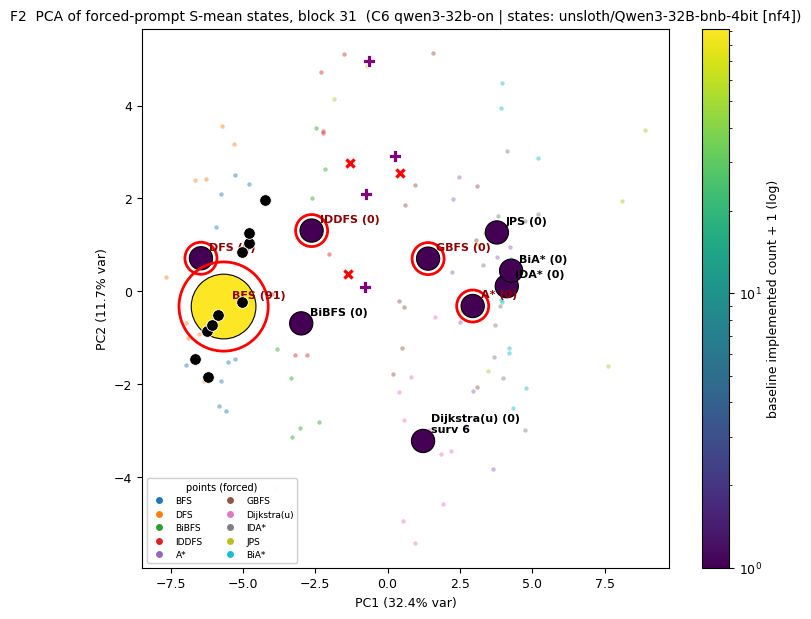

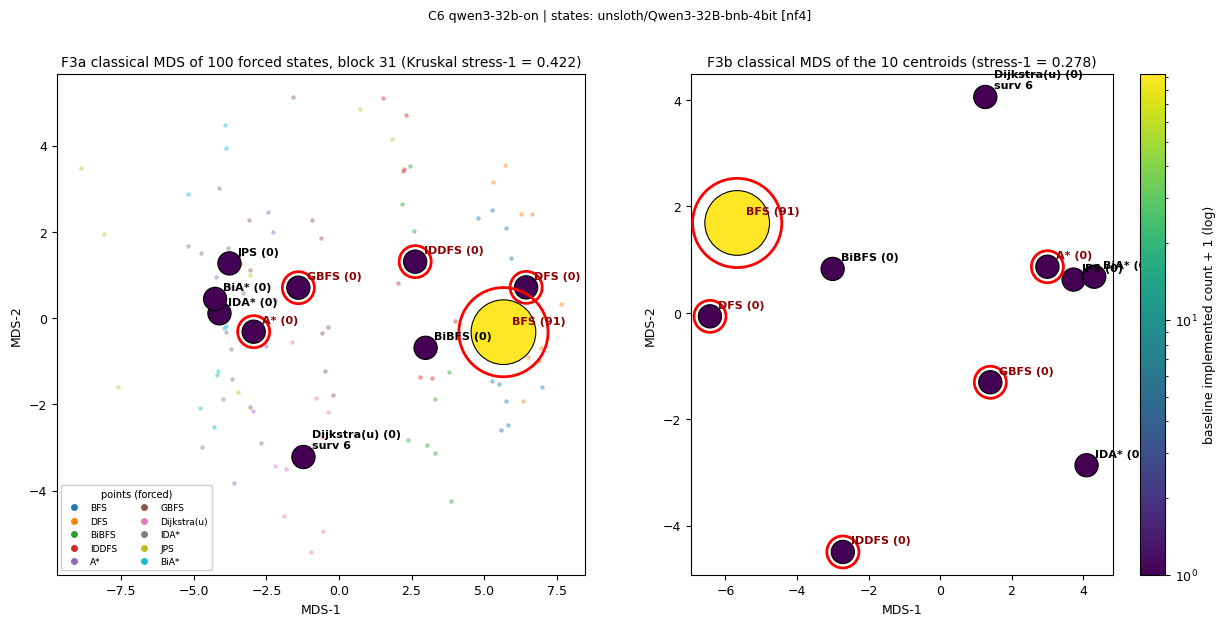

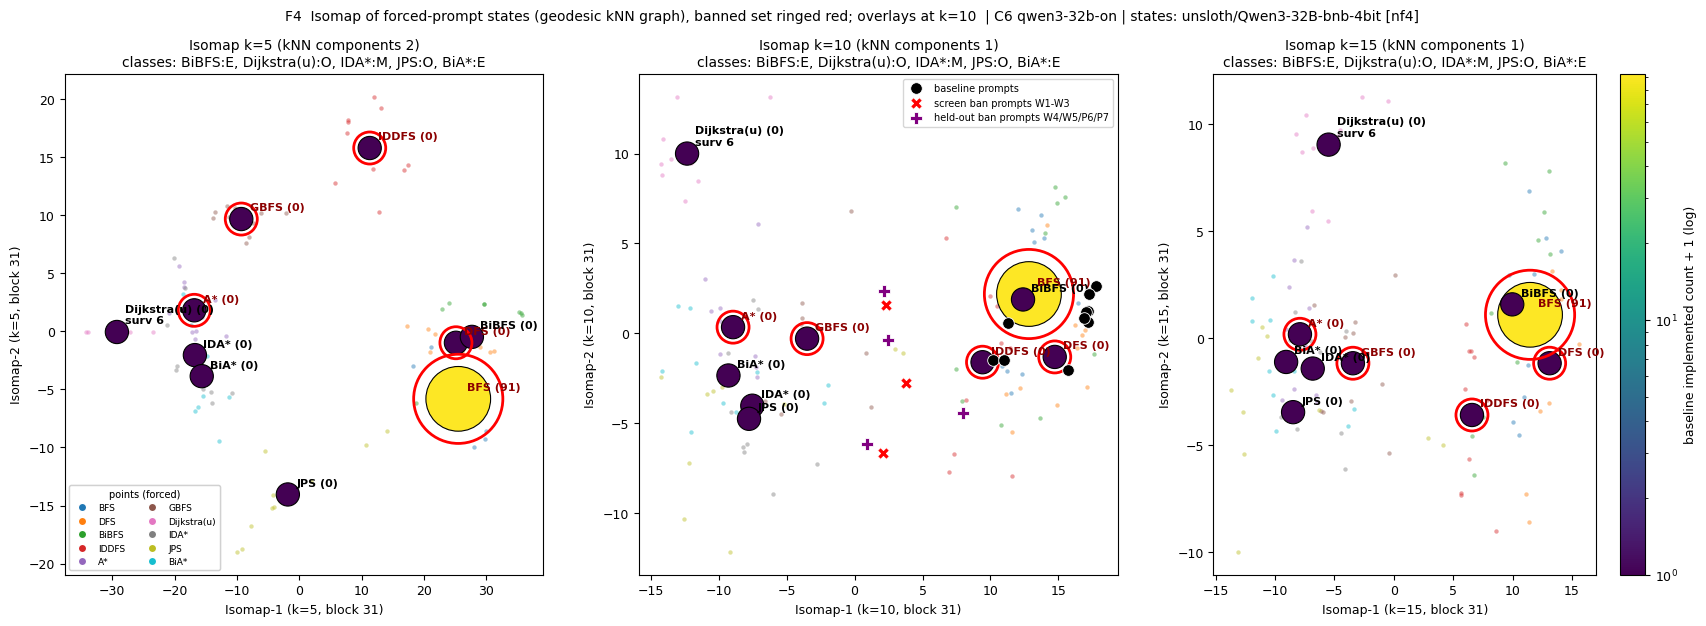

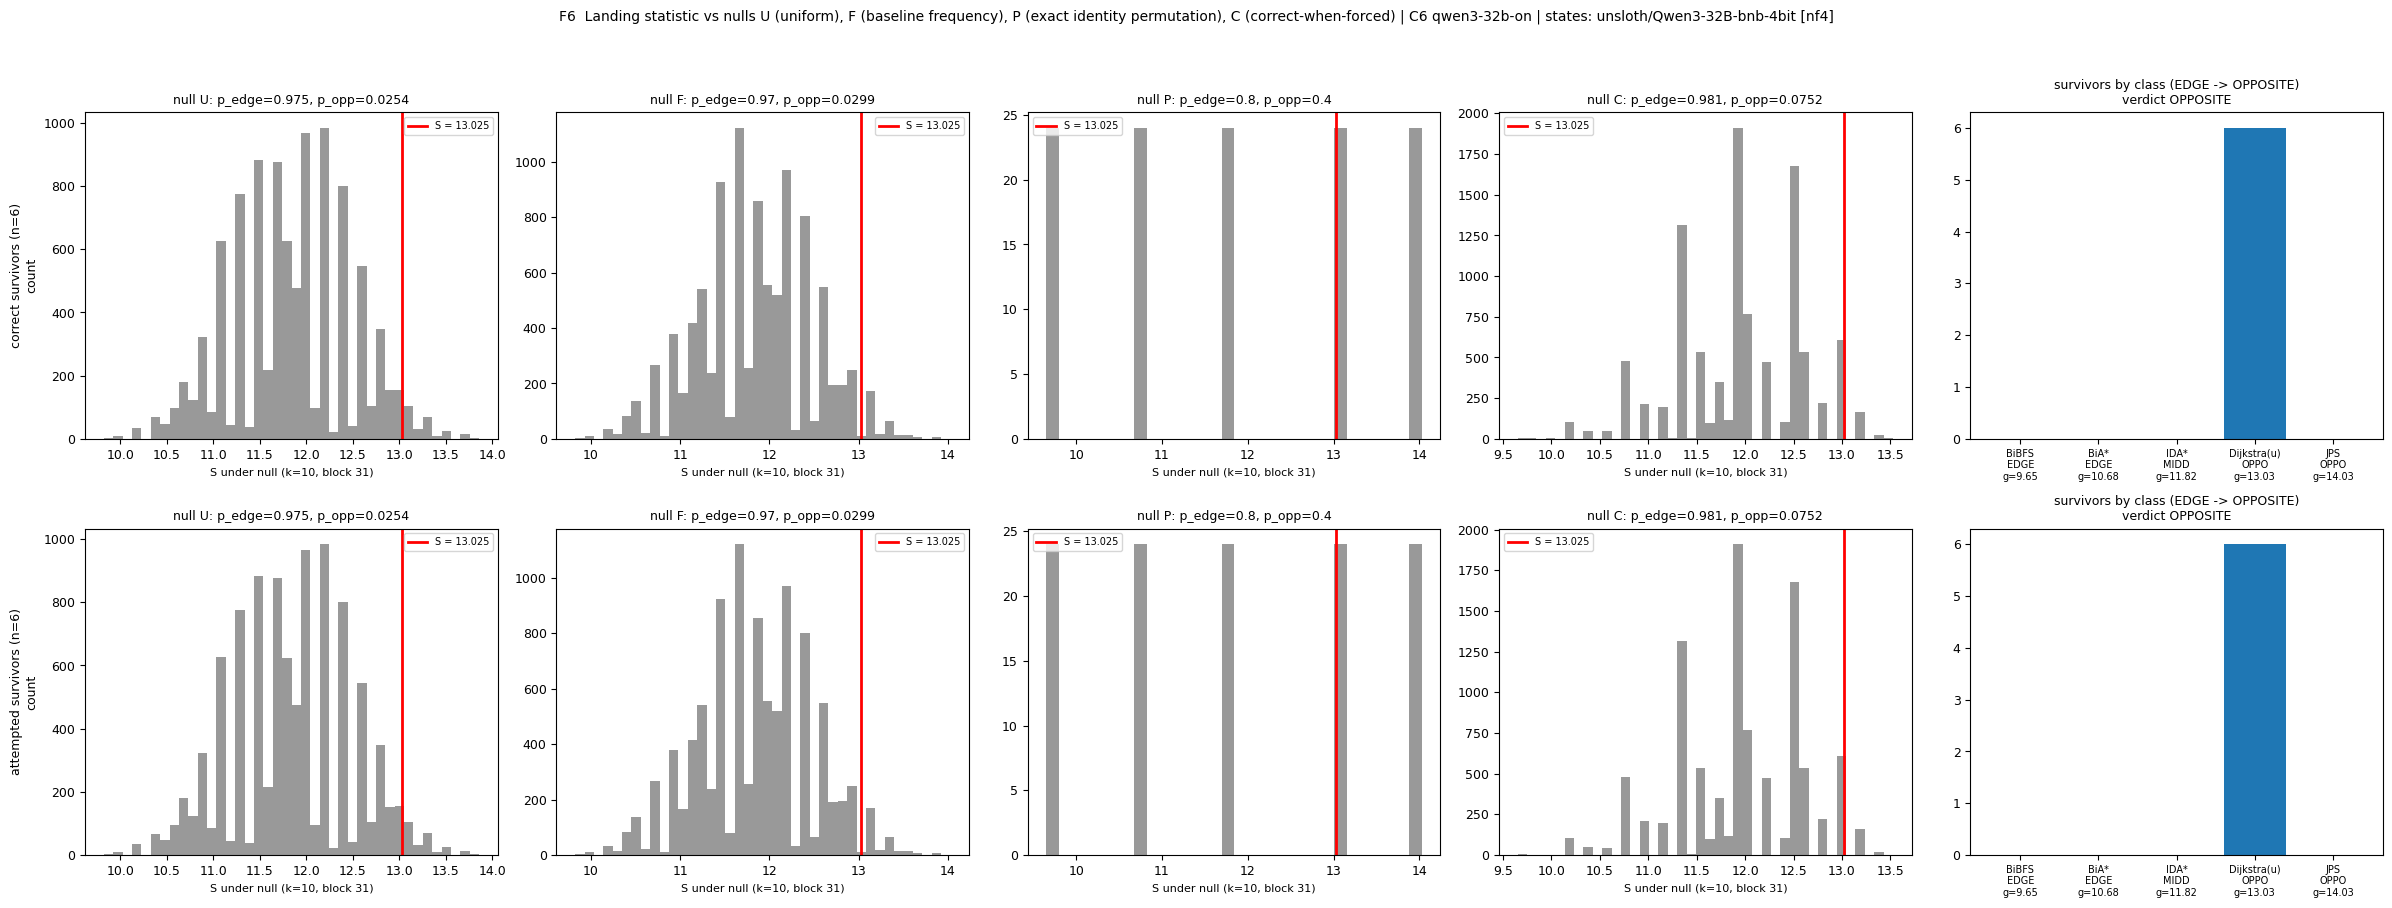

In [24]:
manifold_figures(m, X, labels, banned, impl, over, L, kp, ms, tag, surv, att)
if land.get("_nulls_raw") or land_att.get("_nulls_raw"):
    null_figure(land, land_att, m[f"k{kp}"], ms, L, kp)

## 7. Stage `confirm`: held-out ban templates on the frozen geometry

**What was frozen.** Before any held-out sample, commit #4 froze:
- L\*, k, the point set and the geodesic matrices;
- g, the classes and the null code;
- the verdict rule.

**What was sampled.** C6 was then sampled N = 50 times with four unseen ban templates:
- W4 `'{X} is not allowed here.'`
- W5 `'Write a correct solution that does not use {X}.'`
- P6 `'None of the following may be used in your solution: {X}.'`
- P7 `'Solve this task without using {X}.'`

**Rule.** CONFIRMED iff all three hold, with nothing refit:
- the held-out verdict equals the screen verdict;
- p(U) < 0.05 in that direction;
- a majority of survivors fall in that class.

The sampling and adjudication cannot run here, so their labelled outcomes are loaded. The landing below reuses the geometry computed above unchanged. One rename: the original calls the result `lc`, which here would overwrite the layer curve, so it is `lc_conf`.

In [25]:
# stage_confirm(), after sampling + adjudication: landing of the held-out survivors on the frozen g / classes
rows = rows_m["confirm"]                       # read_jsonl(screen.labelled_path(ms, "confirm")) in the original
surv_c = [r["adj_label"] for r in rows if is_correct_survivor(r, banned) and r["adj_label"] in nonb]   # `surv`
g = m[f"k{kp}"]["g"]
cls = m[f"k{kp}"]["classes"]
lc_conf = landing(g, cls, surv_c, {a: impl.get(a, 0) for a in nonb}, rates, draws=NULL_DRAWS)          # `lc`
sv = land["verdict"]
ok = False
if lc_conf.get("S") is not None and sv in ("EDGE", "OPPOSITE"):
    key = "p_edge" if sv == "EDGE" else "p_opp"
    ok = lc_conf["verdict"] == sv and lc_conf["nulls"]["U"][key] < 0.05 and lc_conf["class_shares"].get(sv, 0) > 0.5
n_cs = sum(is_correct_survivor(r, banned) for r in rows)
conf = {"ran": True, "m_star": ms, "n": len(rows), "survivors": surv_c, "landing": strip(lc_conf),
        "screen_verdict": sv, "CONFIRMED": ok}
logger.info(f"CONFIRMATION {ms}: share_cs {n_cs / len(rows)}, n_surv {len(surv_c)}, verdict {lc_conf['verdict']} vs screen "
            f"{sv} -> CONFIRMED={ok}")
p = lc_conf["nulls"]
print(f"held-out: {n_cs}/{len(rows)} correct survivors (templates {dict(collections.Counter(r['template'] for r in rows))})")
print(f"catalogue survivors {dict(collections.Counter(surv_c))}: S = {lc_conf['S']:.3f}, p_opp U {p['U']['p_opp']:.4f} "
      f"F {p['F']['p_opp']:.4f} P {p['P']['p_opp']:.3f} C {p['C']['p_opp']:.4f} -> {lc_conf['verdict']}, CONFIRMED = {ok}")

11:25:46|INFO   |CONFIRMATION C6: share_cs 0.42, n_surv 9, verdict OPPOSITE vs screen OPPOSITE -> CONFIRMED=True


held-out: 21/50 correct survivors (templates {'W4': 13, 'W5': 13, 'P6': 12, 'P7': 12})
catalogue survivors {'dijkstra_unit': 9}: S = 13.025, p_opp U 0.0115 F 0.0111 P 0.400 C 0.0228 -> OPPOSITE, CONFIRMED = True


**F7** (`stage_figures`): the held-out ban prompt states on the frozen PCA and Isomap axes, annotated with the held-out survivor counts. In the original, `geo` is read back from `results/geometry_M1.json`; here it is the in-memory `res`.

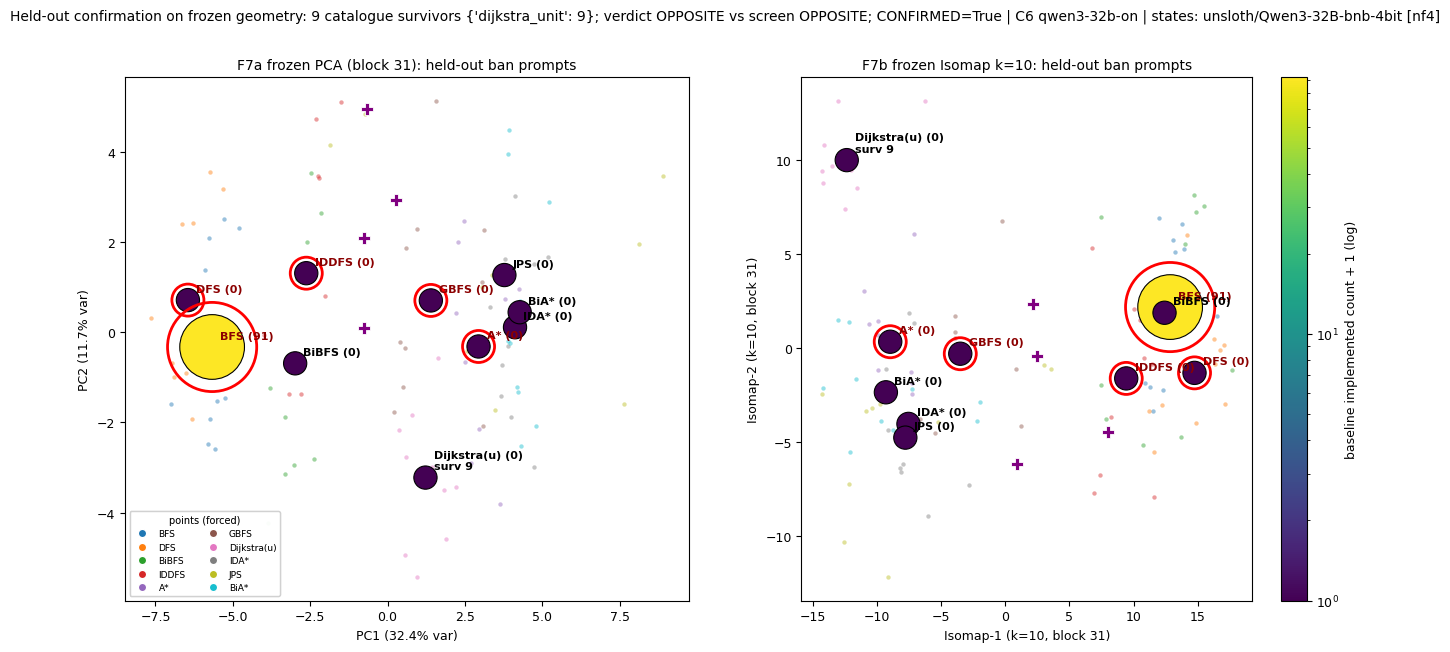

In [26]:
# stage_figures(): F7 from the in-memory geometry (geo = read_json(RESULTS / "geometry_M1.json") in the original)
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap

geo = res
blocks = [int(b) for b in z["blocks"]]
F = z["kind"] == "forced"
X = z["smean"][F][:, blocks.index(geo["L_star"])].astype(np.float64)
labels = z["algorithm"][F]
Qc = z["smean"][z["kind"] == "confirm"][:, blocks.index(geo["L_star"])].astype(np.float64)
kp = geo["M1"]["k_primary"]
pca = PCA(n_components=10, random_state=0).fit(X)          # same fit as M1 (deterministic)
iso = Isomap(n_neighbors=kp, n_components=2)
Y = iso.fit_transform(X)
confirmation_figure(geo, X, labels, conf, dict(impl), Y, iso, pca, Qc, geo["config"])

## 8. Stage `circle` (G7): is the manifold a circle?

If the algorithms sat on a ring, EDGE and OPPOSITE would literally be positions on that ring. The check:
- **Statistic.** The maximum H1 (loop) persistence of a Vietoris–Rips filtration (ripser), computed on the forced points (PCA-20) and on the 10 centroids (PCA-9).
- **Null.** Covariance-matched Gaussian clouds.
- **Rule.** The manifold counts as a circle only if both p-values are < 0.05.

In the full run:
- the 300 points carried some H1 above the null (1.59 vs a 95th percentile of 1.29);
- the 10 centroids carried none (0.00).

So there is no ring at the algorithm level. EDGE and OPPOSITE are geodesic-distance classes on a non-circular manifold.

`stage_circle` is kept as a function, so its local variables do not overwrite the notebook's. Its two file reads are replaced by the in-memory `geo` and `z`, and the number of null clouds is a parameter. Note that its docstring still describes the full run's 300 points.

In [27]:
def stage_circle(n_null: int = 100) -> dict[str, Any]:
    """G7 (optional): ripser H1 on the 300 M1 points (PCA-20) and on the 10 centroids vs 100 covariance-matched
    Gaussian clouds. Descriptive answer to 'is it a circle'."""
    import numpy as np
    from ripser import ripser
    from sklearn.decomposition import PCA

    # notebook: geo = read_json(RESULTS / "geometry_M1.json") and z = _load_smean(geo["tag"]) are the in-memory objects
    F = z["kind"] == "forced"
    blocks = [int(b) for b in z["blocks"]]
    X = z["smean"][F][:, blocks.index(geo["L_star"])].astype(np.float64)
    labels = z["algorithm"][F]
    Z = PCA(n_components=20, random_state=0).fit_transform(X)

    def maxp(A: np.ndarray) -> float:
        d = ripser(A, maxdim=1)["dgms"][1]
        return float((d[:, 1] - d[:, 0]).max()) if len(d) else 0.0

    obs = maxp(Z)
    rng = np.random.default_rng(0)
    cov, mu = np.cov(Z.T), Z.mean(0)
    null = [maxp(rng.multivariate_normal(mu, cov, size=len(Z))) for _ in range(n_null)]
    C = np.stack([X[labels == a].mean(0) for a in CANON_ORDER])
    Cz = PCA(n_components=9, random_state=0).fit_transform(C)
    obs_c = maxp(Cz)
    covc, muc = np.cov(Cz.T), Cz.mean(0)
    null_c = [maxp(rng.multivariate_normal(muc, covc, size=10)) for _ in range(n_null)]
    out = {"points": {"max_H1_persistence": obs, "null_q95": float(np.quantile(null, 0.95)),
                      "p": float(np.mean(np.array(null) >= obs))},
           "centroids": {"max_H1_persistence": obs_c, "null_q95": float(np.quantile(null_c, 0.95)),
                         "p": float(np.mean(np.array(null_c) >= obs_c))},
           "L_star": geo["L_star"], "config": geo["config"]}
    out["is_circle"] = bool(out["points"]["p"] < 0.05 and out["centroids"]["p"] < 0.05)
    # the original writes out -> results/circle_check.json
    logger.info(f"circle check: {out}")
    return out


t0 = time.time()
circle = stage_circle(n_null=CIRCLE_NULLS)
print(f"is it a circle? {circle['is_circle']}  (points p = {circle['points']['p']:.2f}, centroids p = "
      f"{circle['centroids']['p']:.2f}; {CIRCLE_NULLS} null clouds)   [{time.time() - t0:.1f}s]")

11:25:48|INFO   |circle check: {'points': {'max_H1_persistence': 1.9759187698364258, 'null_q95': 1.3348111867904662, 'p': 0.0}, 'centroids': {'max_H1_persistence': 0.0, 'null_q95': 0.7833916902542114, 'p': 1.0}, 'L_star': 31, 'config': 'C6', 'is_circle': False}


is it a circle? False  (points p = 0.00, centroids p = 1.00; 100 null clouds)   [0.7s]


## 9. Check T8: does the pipeline find a planted answer? (synthetic ring)

The same geometry and landing code runs on synthetic data where the answer is known: 10 Gaussian clusters on a ring in 50 dimensions, in canonical order, with the five contiguous clusters 0–4 banned. The pipeline must pass five checks:
- **Planted EDGE.** Survivors at the two ring neighbours of the banned arc must give **EDGE** (p_edge(U) < 0.05).
- **Permutation floor.** The algorithm-level permutation p must sit at its floor of 0.2.
- **Planted OPPOSITE.** Survivors at the far side must give **OPPOSITE**.
- **Placebo.** Random survivor labels must give directional verdicts at roughly the nominal rate (≤ 12%).
- **Ring recovery.** ripser must find the ring's H1 above Gaussian clouds.

In the full run all five passed, with 11% false directional verdicts in 200 placebo runs. `stage_t8` is kept as a function, and its result is returned instead of being written to `results/t8_synthetic.json`.

In [28]:
def synthetic_ring(n_per: int = 30, dim: int = 50, radius: float = 10.0, noise: float = 1.0,
                   seed: int = 0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """T8: 10 Gaussian clusters on a ring (algorithms in canonical order around the ring)."""
    rng = np.random.default_rng(seed)
    X, lab, grp = [], [], []
    basis = np.linalg.qr(rng.normal(size=(dim, 2)))[0]
    for i, a in enumerate(CANON_ORDER):
        th = 2 * np.pi * i / 10
        c = radius * (np.cos(th) * basis[:, 0] + np.sin(th) * basis[:, 1])
        X.append(c + noise * rng.normal(size=(n_per, dim)) / np.sqrt(dim) * 3)
        lab += [a] * n_per
        grp += list(range(n_per))
    return np.concatenate(X), np.array(lab), np.array(grp)


def stage_t8(n_random: int = 200, n_null: int = 20) -> dict[str, Any]:
    """T8: geometry + landing on synthetic data (ring of 10 Gaussian clusters, 5 contiguous banned)."""
    import numpy as np

    X, lab, grp = synthetic_ring()
    banned = CANON_ORDER[:5]            # contiguous on the ring: positions 0-4
    nonb = CANON_ORDER[5:]              # 5..9; ring neighbours of the banned arc are positions 5 and 9
    m = manifold(X, lab, banned, fit_isomap=False)
    kp = m["k_primary"]
    g = m[f"k{kp}"]["g"]
    cls = m[f"k{kp}"]["classes"]
    edge_planted = [CANON_ORDER[5]] * 6 + [CANON_ORDER[9]] * 6
    opp_planted = [CANON_ORDER[7]] * 12
    le = landing(g, cls, edge_planted, {a: 0 for a in nonb}, {a: 0.5 for a in nonb})
    lo = landing(g, cls, opp_planted, {a: 0 for a in nonb}, {a: 0.5 for a in nonb})
    rng = np.random.default_rng(1)
    verdicts = []
    for r in range(n_random):
        surv = list(rng.choice(nonb, size=12))
        verdicts.append(landing(g, cls, surv, {a: 0 for a in nonb}, {a: 0.5 for a in nonb},
                                draws=2000, seed=r)["verdict"])
    import collections
    vc = collections.Counter(verdicts)
    from ripser import ripser
    from sklearn.decomposition import PCA
    Z = PCA(n_components=20, random_state=0).fit_transform(X)
    dg = ripser(Z, maxdim=1)["dgms"][1]
    maxp = float((dg[:, 1] - dg[:, 0]).max()) if len(dg) else 0.0
    nullp = []
    for s in range(n_null):
        G = np.random.default_rng(100 + s).multivariate_normal(Z.mean(0), np.cov(Z.T), size=len(Z))
        d2 = ripser(G, maxdim=1)["dgms"][1]
        nullp.append(float((d2[:, 1] - d2[:, 0]).max()) if len(d2) else 0.0)
    out = {"g": g, "classes": cls, "edge_planted": strip(le), "opp_planted": strip(lo),
           "random_200": dict(vc), "random_false_directional_rate": (vc["EDGE"] + vc["OPPOSITE"]) / n_random,
           "ripser_ring_maxH1": maxp, "ripser_gauss_null_max": max(nullp),
           "pass": {"edge": le["verdict"] == "EDGE" and le["nulls"]["U"]["p_edge"] < 0.05,
                    "perm_at_floor": le["nulls"]["P"]["p_edge"] <= 0.2 + 1e-9,
                    "opposite": lo["verdict"] == "OPPOSITE",
                    "random_nominal": (vc["EDGE"] + vc["OPPOSITE"]) / n_random <= 0.12,
                    "ring_recovered": maxp > max(nullp)}}
    # the original writes out -> results/t8_synthetic.json ("random_200" holds the n_random placebo verdicts)
    logger.info(f"T8: classes {cls}; edge verdict {le['verdict']} pU={le['nulls']['U']['p_edge']:.4f} "
                f"pP={le['nulls']['P']['p_edge']:.3f}; opp verdict {lo['verdict']}; random {dict(vc)}; ripser "
                f"{maxp:.2f} vs null max {max(nullp):.2f}; pass {out['pass']}")
    return out


t0 = time.time()
t8 = stage_t8(n_random=T8_RANDOM, n_null=T8_NULLS)
print(f"T8 checks passed: {sum(t8['pass'].values())}/5 {t8['pass']}   [{time.time() - t0:.1f}s]")

11:25:50|INFO   |T8: classes {'gbfs': 'EDGE', 'dijkstra_unit': 'MIDDLE', 'idastar': 'OPPOSITE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'}; edge verdict EDGE pU=0.0001 pP=0.100; opp verdict OPPOSITE; random {'NEITHER': 178, 'OPPOSITE': 10, 'EDGE': 12}; ripser 11.58 vs null max 3.40; pass {'edge': True, 'perm_at_floor': True, 'opposite': True, 'random_nominal': True, 'ring_recovered': True}


T8 checks passed: 5/5 {'edge': True, 'perm_at_floor': True, 'opposite': True, 'random_nominal': True, 'ring_recovered': True}   [2.4s]


## 10. Results

**F1** (`stage_figures`): the screen forest plot. It shows each configuration's share of correct survivors under the literal five-name ban, with its Wilson 95% interval. The red line is the committed 0.20 selection bar; carried rows are grey.

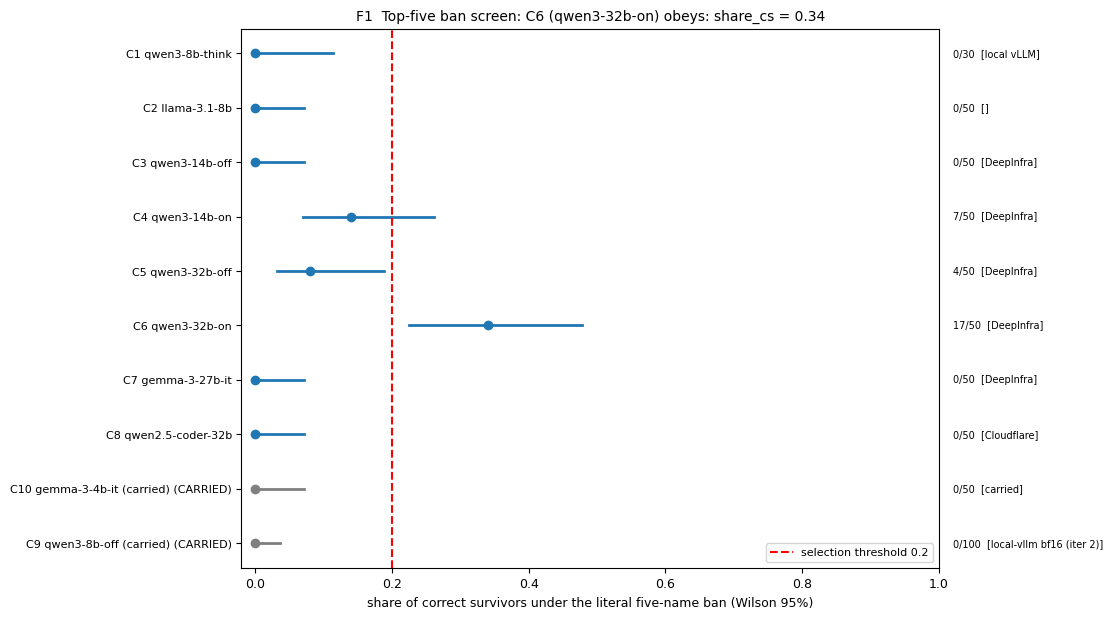

In [29]:
forest(tab, sel)

**Demo vs. full run.** The table puts this notebook's numbers (100 forced points, the draws set in the config cell) next to the full run's (300 points, from `results/*.json`). The plot has three panels:
- **(a)** each non-banned algorithm's distance to the banned five, divided by the median: below 1 is EDGE, above 1 is OPPOSITE;
- **(b, c)** the block × k robustness grids of the demo and of the full run.

**Reading the result.**
- **Who obeys.** Only C6, Qwen3-32B with thinking on, clears the bar. Most of its "obedience" consists of known algorithms outside the catalogue, mainly Bellman-Ford/SPFA. Disobedient programs mostly re-implement BFS/DFS without naming them.
- **Where the survivors land.** Every catalogue survivor is unit-weight Dijkstra. On the model's own manifold, Dijkstra is the non-banned algorithm *farthest* from the banned five, so the verdict is **OPPOSITE**, not the pre-registered EDGE. The held-out templates confirm it.
- **Caveats.**
  - The per-program nulls (U, F) overstate the evidence. With a single landing algorithm, the honest algorithm-level p is the permutation floor of 0.2.
  - The verdict is not robust across k.
  - The result is correlational: in iteration 7, in-manifold pushes moved 0/300 programs.

                                          demo (this notebook)                              full run (results/*.json)                         
----------------------------------------------------------------------------------------------------------------------------------------------
forced points (per algorithm)             100 (10)                                          300 (30)                                          
selection: Q -> m*                        ['C6'] -> C6                                      ['C6'] -> C6                                      
L* (rule)                                 31 (all blocks at ceiling)                        31 (all blocks at ceiling)                        
PCA EVR PC1 / PC2                         0.324 / 0.117                                     0.324 / 0.120                                     
MDS stress-1 points / centroids           0.42 / 0.28                                       0.42 / 0.28                                       

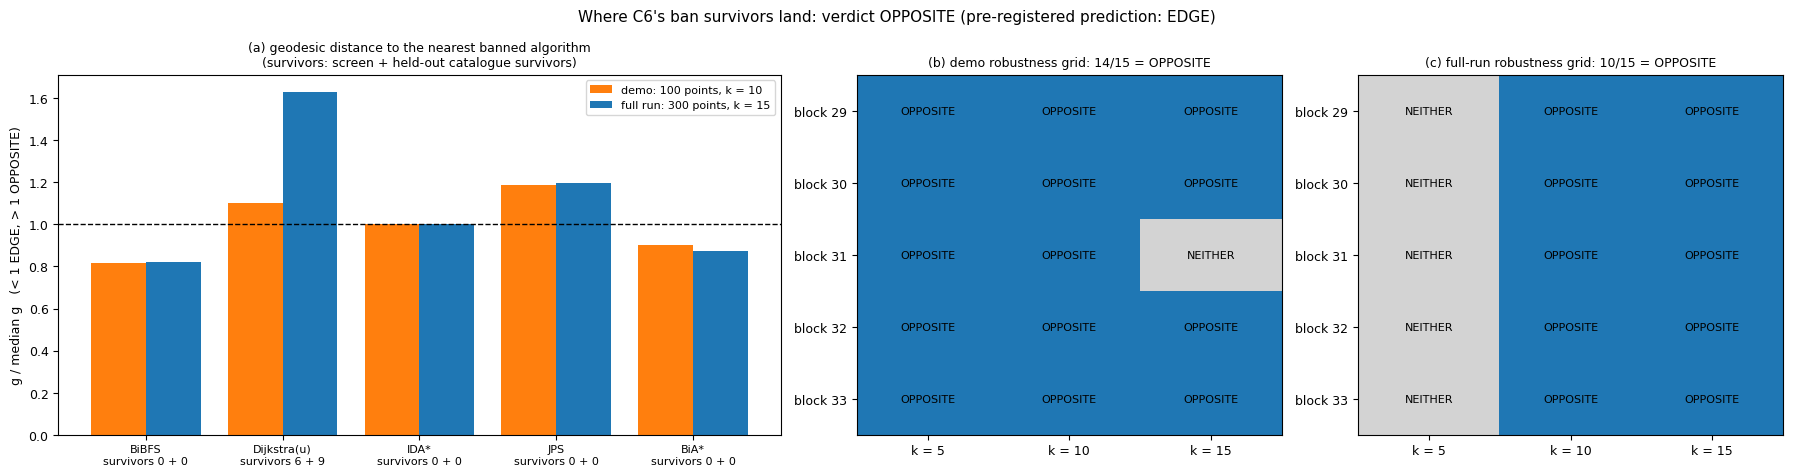

In [30]:
from matplotlib.colors import ListedColormap

ref = meta["full_run_reference"]
kr = ref["k_primary"]
cl = lambda c: " ".join(f"{SHORT[a]}:{v[0]}" for a, v in c.items())            # class initials E / M / O
pp = lambda p: " / ".join(f"{p[k]['p_opp']:.3g}" for k in ("U", "F", "P", "C"))
rule = lambda r: "all blocks at ceiling" if r.startswith("all") else "argmax"
summary = [
    ("forced points (per algorithm)", f"{len(X)} ({len(X) // 10})", f"{ref['n_forced_points']} (30)"),
    ("selection: Q -> m*", f"{sel['Q']} -> {ms}", f"{ref['selection']['Q']} -> {ref['selection']['m_star']}"),
    ("L* (rule)", f"{L} ({rule(lc['rule'])})", f"{ref['L_star']} ({rule(ref['layer_rule'])})"),
    ("PCA EVR PC1 / PC2", f"{m['pca_evr'][0]:.3f} / {m['pca_evr'][1]:.3f}",
     f"{ref['pca_evr_2'][0]:.3f} / {ref['pca_evr_2'][1]:.3f}"),
    ("MDS stress-1 points / centroids", f"{m['mds_points_stress1']:.2f} / {m['mds_centroids_stress1']:.2f}",
     f"{ref['mds_points_stress1']:.2f} / {ref['mds_centroids_stress1']:.2f}"),
    ("kNN components k = 5 / 10 / 15", " / ".join(str(m[f"k{k}"]["components_before_join"]) for k in (5, 10, 15)),
     " / ".join(str(ref["per_k"][str(k)]["components_before_join"]) for k in (5, 10, 15))),
    ("primary k", kp, kr),
    ("classes at primary k", cl(m[f"k{kp}"]["classes"]), cl(ref["per_k"][str(kr)]["classes"])),
    ("split-half Spearman k = 5 / 10 / 15", " / ".join(f"{rel['split_half'][k]['spearman_offdiag']:.2f}" for k in (5, 10, 15)),
     " / ".join(f"{ref['split_half_spearman'][str(k)]:.2f}" for k in (5, 10, 15))),
    ("bootstrap: Dijkstra(u) keeps its class", f"{rel['bootstrap']['class_stability']['dijkstra_unit']:.2f} ({N_BOOT} resamples)",
     f"{ref['bootstrap']['class_stability']['dijkstra_unit']:.2f} ({ref['bootstrap']['n_boot']} resamples)"),
    ("screen catalogue survivors", f"{dict(collections.Counter(surv))}", f"n = {ref['landing']['n_surv']} (same rows)"),
    ("landing S", f"{land['S']:.2f}", f"{ref['landing']['S']:.2f}"),
    ("p_opp  U / F / P / C", pp(land["nulls"]), pp(ref["landing"]["p"])),
    ("verdict (pre-registered: EDGE)", land["verdict"], ref["landing"]["verdict"]),
    ("robustness: cells = primary verdict", f"{rob['identical_to_primary']}/{rob['n_cells']}, ROBUST = {rob['ROBUST']}",
     f"{ref['robustness']['verdict_counts'].get(ref['landing']['verdict'], 0)}/15, ROBUST = {ref['robustness']['ROBUST']}"),
    ("held-out: survivors, verdict, CONFIRMED", f"{len(surv_c)}, {lc_conf['verdict']}, {conf['CONFIRMED']}",
     f"{ref['confirmation']['n_surv']}, {ref['confirmation']['verdict']}, {ref['confirmation']['CONFIRMED']}"),
    ("ban prompts: rank of Dijkstra(u) centroid", f"{place['ban']['rank_of_dijkstra_unit']}/10",
     f"{ref['prompt_state_placement']['ban']['rank_of_dijkstra_unit']}/10"),
    ("circle? (points p / centroids p)", f"{circle['is_circle']} ({circle['points']['p']:.2f} / {circle['centroids']['p']:.2f})",
     f"{ref['circle_check']['is_circle']} ({ref['circle_check']['points']['p']:.2f} / {ref['circle_check']['centroids']['p']:.2f})"),
    ("T8 synthetic-ring checks passed", f"{sum(t8['pass'].values())}/5", f"{sum(ref['t8_synthetic']['pass'].values())}/5"),
]
print(f"{'':42s}{'demo (this notebook)':50s}{'full run (results/*.json)':50s}")
print("-" * 142)
for name, a, b in summary:
    print(f"{name:42s}{str(a):50s}{str(b):50s}")

# (a) distance of each non-banned algorithm to the banned five; (b, c) robustness grids
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.7, 1, 1]})
xs = np.arange(len(nonb))
for off, gg, lab_, col in ((-0.2, m[f"k{kp}"]["g"], f"demo: {len(X)} points, k = {kp}", "tab:orange"),
                           (0.2, ref["per_k"][str(kr)]["g"], f"full run: {ref['n_forced_points']} points, k = {kr}", "tab:blue")):
    med = float(np.median(list(gg.values())))
    axs[0].bar(xs + off, [gg[a] / med for a in nonb], width=0.4, color=col, label=lab_)
axs[0].axhline(1.0, color="k", ls="--", lw=1)
sc_, cc_ = collections.Counter(surv), collections.Counter(surv_c)
axs[0].set_xticks(xs)
axs[0].set_xticklabels([f"{SHORT[a]}\nsurvivors {sc_[a]} + {cc_[a]}" for a in nonb], fontsize=8)
axs[0].set_ylabel("g / median g   (< 1 EDGE, > 1 OPPOSITE)")
axs[0].set_title("(a) geodesic distance to the nearest banned algorithm\n(survivors: screen + held-out catalogue survivors)",
                 fontsize=9)
axs[0].legend(fontsize=8)
VC = {"EDGE": 0, "NEITHER": 1, "OPPOSITE": 2}
for ax, cells, title in ((axs[1], {c: v["verdict"] for c, v in grid.items()},
                          f"(b) demo robustness grid: {rob['identical_to_primary']}/{rob['n_cells']} = {primary}"),
                         (axs[2], ref["robustness"]["cells"],
                          f"(c) full-run robustness grid: {ref['robustness']['verdict_counts'].get(ref['landing']['verdict'], 0)}"
                          f"/15 = {ref['landing']['verdict']}")):
    bl = sorted({int(c.split("_")[0][1:]) for c in cells})
    M = np.array([[VC[cells[f"L{b}_k{k}"]] for k in (5, 10, 15)] for b in bl])
    ax.imshow(M, cmap=ListedColormap(["tab:green", "lightgrey", "tab:blue"]), vmin=0, vmax=2, aspect="auto")
    for i, b in enumerate(bl):
        for j, k in enumerate((5, 10, 15)):
            ax.text(j, i, cells[f"L{b}_k{k}"], ha="center", va="center", fontsize=8)
    ax.set_xticks(range(3))
    ax.set_xticklabels([f"k = {k}" for k in (5, 10, 15)])
    ax.set_yticks(range(len(bl)))
    ax.set_yticklabels([f"block {b}" for b in bl])
    ax.set_title(title, fontsize=9)
fig.suptitle(f"Where {ms}'s ban survivors land: verdict {land['verdict']} (pre-registered prediction: EDGE)", fontsize=11)
fig.tight_layout()
plt.show()